# 07 — Results Analysis: EFCIL × Attention untuk Scene Classification Citra Satelit

**Tujuan:** melakukan audit dan analisis **hasil production**, bukan smoke/profiling. Notebook ini membaca hasil `run_experiment()` dari PyCIL; **tidak memulai training**, tidak memodifikasi checkpoint, dan dapat dijalankan ketika sebagian eksperimen belum selesai.

Urutan: **(1)** konfigurasi sumber data → **(2)** audit kelengkapan & konsistensi → **(3)** coverage eksperimen → **(4)** tabel AIA/LTA/FR/BWT/Macro-F1 → **(5)** paired attention gain → **(6)** grafik akurasi per task & confusion matrix → **(7)** ekspor laporan.

**Metodologi yang dikunci:** AID 600×600, NWPU 256×256; seed split/class-order 1993; AID T5 `[14,4,4,4,4]` / T10 `[12,2×9]`; NWPU T5 `[25,5×4]` / T10 `[18,3×9]`; empat attention `none`, `eca`, `cbam`, `procbam`. Evaluasi menggunakan classifier canonical yang telah digunakan runner (FeTrIL = Linear SVM; FeCAM = Mahalanobis; PASS/SSRE/EFC = output CNN canonical), sehingga **tidak melakukan inferensi ulang**.

### Interpretasi statistik
- **AIA** = rata-rata akurasi joint pada semua task, **LTA** = akurasi joint task terakhir.
- **ΔAIA** = AIA(attention) − AIA(none) pada **dataset × metode × T × backbone × seed** yang sama; dilaporkan dalam *percentage points (pp)*.
- **Mean ΔAIA / Attention Gain** = rata-rata delta atas *paired runs* yang tersedia, **bukan** rata-rata semua angka absolut tanpa pasangan.
- **Win Rate** = proporsi paired runs dengan ΔAIA > 0.
- Standar deviasi delta yang ditampilkan adalah variasi antarkondisi backbone/T, **bukan antarseed**. Dengan satu seed, **jangan mengklaim signifikansi statistik**.
- FR/BWT diambil dari metrik canonical runner; FWT berstatus **not applicable**, tidak diisi nilai palsu.

> Keamanan: file `.npz`/`.npy` dibaca dengan `allow_pickle=False`. Notebook **tidak** membuka `.pkl` secara otomatis. Checkpoint dicek keberadaan/ukuran dan manifest-nya. Pemeriksaan loadable penuh harus dilakukan pada lingkungan repository tepercaya menggunakan verifier production terpisah.

**Update 12 November 2026:** Bagian akhir notebook mengekspor **Tabel 4.1–4.16**, **Gambar 4.1–4.17** (300 dpi), dan enam visual tambahan opsional secara langsung dari ZIP AI-ready + feature-space. Metrik canonical tidak dimodifikasi.


## 1. Setup & direktori sumber

**Disarankan menjalankan notebook ini pada PC2** setelah mengumpulkan hasil server. Struktur contoh:

```text
PyCIL/
├── outputs/experiments/                        # hasil lokal PC2
├── analysis_inputs/server/experiments/          # hasil export server, ekstraksi ZIP
├── notebooks/07_results_analysis.ipynb
└── outputs/analysis/                             # CSV, JSON, PNG dari notebook
```

Untuk menyalin hasil server tanpa `.pkl` model yang berukuran besar, gunakan script pendamping `scripts/export_evaluation_artifacts.py`; ia mencatat **checkpoint inventory** (bukti file ada pada mesin sumber saat ekspor). Hasil ekspor tanpa bobot checkpoint akan ditandai `ready_snapshot`, bukan `ready_full`. Jika Anda menyalin semua file termasuk `.pkl`, status dapat menjadi `ready_full`.

Jika notebook dijalankan pada server atau lokasi lain, sesuaikan `SOURCES`. Jangan menghapus hasil run lama atau menganggap status `completed` saja cukup.

In [1]:
from __future__ import annotations

import io, json, math, re, warnings, zipfile
from pathlib import Path
from datetime import datetime
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Lokasi otomatis untuk notebook di PyCIL/ atau PyCIL/notebooks/
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

# EDIT PATH di sini bila menjalankan dari komputer berbeda.
SOURCES = {
    "pc2": PROJECT_ROOT / "outputs" / "experiments",
    "server": PROJECT_ROOT / "analysis_inputs" / "server" / "experiments",
}
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "analysis"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables_bab4"
AI_READY_DIR = PROJECT_ROOT / "outputs" / "analysis_ai_ready"
AI_CROSSCHECK_DIR = OUTPUT_DIR / "ai_crosscheck"
for path in (OUTPUT_DIR, FIG_DIR, TABLE_DIR, AI_CROSSCHECK_DIR):
    path.mkdir(parents=True, exist_ok=True)

# File .pkl tidak dibuka; model checkpoint hanya dicek keberadaan dan ukuran.
ALLOW_CHECKPOINT_INVENTORY = True   # izinkan ready_snapshot dari ZIP export
EXPECTED_SEED = 1993
DATASET_SCOPE = "aid"               # gunakan None untuk semua dataset yang ditemukan
GENERATE_FIGURES = True

ATTENTIONS = ("none", "eca", "cbam", "procbam")
PAIR_ATTENTIONS = ("eca", "cbam", "procbam")
METHODS = ("fetril", "fecam", "ssre", "efc", "pass")
BACKBONES = ("r18", "r34")
PROTOCOLS = ("T5", "T10")
METHOD_LABELS = {"fetril": "FeTrIL", "fecam": "FeCAM", "ssre": "SSRE", "efc": "EFC", "pass": "PASS"}
ATTN_LABELS = {"none": "None", "eca": "ECA", "cbam": "CBAM", "procbam": "ProCBAM"}

print("PROJECT_ROOT:", PROJECT_ROOT)
for name, path in SOURCES.items():
    print(f"{name:>8}:", path, "| exists:", path.is_dir())
print("Output:", OUTPUT_DIR)
print("Figures:", FIG_DIR)
print("Tables:", TABLE_DIR)
print("AI crosscheck:", AI_CROSSCHECK_DIR)


PROJECT_ROOT: C:\Skripsi\Project\PyCIL
     pc2: C:\Skripsi\Project\PyCIL\outputs\experiments | exists: True
  server: C:\Skripsi\Project\PyCIL\analysis_inputs\server\experiments | exists: True
Output: C:\Skripsi\Project\PyCIL\outputs\analysis
Figures: C:\Skripsi\Project\PyCIL\outputs\analysis\figures
Tables: C:\Skripsi\Project\PyCIL\outputs\analysis\tables_bab4
AI crosscheck: C:\Skripsi\Project\PyCIL\outputs\analysis\ai_crosscheck


## 2. Fungsi audit dan ekstraksi metadata

Audit menggunakan schema `production_section.py` yang sudah kita bahas: `status.json`, `config.json`, `effective_args.json`, `provenance.json`, `summary.json`, `continual_metrics.json`, `task_metrics.json`, prediksi `task_XX.npz`, confusion matrix per task/final, dan tiga checkpoint artifact per task.

Sebuah run hanya masuk analisis jika **semua task selesai dan evaluasinya konsisten**. ZIP export tanpa bobot model tetap dapat digunakan untuk *analisis metrik* bila inventory checkpoint menyatakan ada file-file itu pada sumber, tetapi perlu diverifikasi kembali di sumber untuk audit final.

In [2]:
def read_json(path: Path):
    with path.open("r", encoding="utf-8-sig") as fh:
        return json.load(fh)


def numeric(value):
    if isinstance(value, bool) or value is None:
        return np.nan
    try:
        result = float(value)
        return result if np.isfinite(result) else np.nan
    except (ValueError, TypeError):
        return np.nan


def safe_float(value):
    value = numeric(value)
    return None if pd.isna(value) else float(value)


def select_value(documents, keys):
    """Ambil nilai dari config/args/provenance tanpa menebak bila tidak ada."""
    for doc in documents:
        if not isinstance(doc, dict):
            continue
        for key in keys:
            if key in doc and doc[key] is not None and not isinstance(doc[key], (dict, list)):
                return doc[key]
        for container in ("config", "args", "experiment", "training", "run_config"):
            sub = doc.get(container)
            if isinstance(sub, dict):
                for key in keys:
                    if key in sub and sub[key] is not None and not isinstance(sub[key], (dict, list)):
                        return sub[key]
    return None


def normalize_metadata(value, kind):
    if value is None:
        return None
    s = str(value).strip().lower().replace("-", "_")
    if kind == "dataset":
        if "resisc" in s or "nwpu" in s: return "nwpu"
        if s in ("aid", "aid30", "aid_dataset"): return "aid"
    if kind == "method":
        for m in METHODS:
            if s == m or s == f"{m}_learner": return m
    if kind == "protocol":
        if s in ("5", "t5", "t_5"): return "T5"
        if s in ("10", "t10", "t_10"): return "T10"
    if kind == "backbone":
        if re.search(r"(?:^|_)r18(?:_|$)", s) or "resnet18" in s or "resnet_18" in s: return "r18"
        if re.search(r"(?:^|_)r34(?:_|$)", s) or "resnet34" in s or "resnet_34" in s: return "r34"
    if kind == "attention":
        if s in ("none", "baseline", "no_attention", "no_attn", "null"): return "none"
        for a in ("procbam", "cbam", "eca"):
            if re.search(r"(?:^|_)" + a + r"(?:_|$)", s): return a
        # Hanya infer none jika field attention sendiri explicit; jangan dari 'r18'.
    if kind == "seed":
        try: return int(value)
        except (ValueError, TypeError): return None
    if kind == "batch":
        try: return int(value)
        except (ValueError, TypeError): return None
    return None


def infer_from_run_name(run_id, kind):
    s = str(run_id).lower().replace("-", "_")
    if kind == "method":
        for m in METHODS:
            if re.search(r"(?:^|_)" + m + r"(?:_|$)", s): return m
    if kind == "dataset":
        for token, normalized in (("aid", "aid"), ("nwpu", "nwpu"), ("resisc45", "nwpu")):
            if re.search(r"(?:^|_)" + token + r"(?:_|$)", s): return normalized
    if kind == "protocol":
        m = re.search(r"(?:^|_)t(5|10)(?:_|$)", s)
        if m: return "T" + m.group(1)
    if kind == "backbone":
        m = re.search(r"(?:^|_)(r18|r34)(?:_|$)", s)
        if m: return m.group(1)
    if kind == "attention":
        for a in ATTENTIONS:
            if re.search(r"(?:^|_)" + a + r"(?:_|$)", s): return a
    if kind == "seed":
        m = re.search(r"(?:^|_)seed_?(\d+)(?:_|$)", s)
        if m: return int(m.group(1))
    return None


def metadata_from_files(run_id, config, args, provenance, summary):
    docs = [config, args, provenance, summary]
    names = {
        "dataset": ["dataset", "dataset_name"],
        "method": ["method", "model_name", "learner_name"],
        "protocol": ["protocol", "task_protocol", "task_setting", "scenario"],
        "backbone": ["backbone", "backbone_type", "backbone_name", "convnet_type"],
        "attention": ["attention", "attention_type", "attention_name", "attn_type"],
        "seed": ["training_seed", "seed", "random_seed"],
        "batch": ["batch_size", "batch"],
    }
    result = {}
    for kind, aliases in names.items():
        raw = select_value(docs, aliases)
        val = normalize_metadata(raw, kind)
        if val is None and kind == "attention":
            # convnet_type/backbone id kadang berupa r34_procbam.
            val = normalize_metadata(select_value(docs, ["convnet_type", "backbone"]), "attention")
        if val is None:
            val = infer_from_run_name(run_id, kind)
        result[kind] = val
    return result


def canonical_primary_top1(primary):
    if not isinstance(primary, dict): return None
    if primary.get("top1") is not None: return safe_float(primary["top1"])
    metric = primary.get("metrics")
    if isinstance(metric, dict): return safe_float(metric.get("top1"))
    return None


def macro_f1_from_confusion(cm):
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    pred = cm.sum(axis=0)
    true = cm.sum(axis=1)
    denom = pred + true
    f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return float(np.mean(f1) * 100.0)


def checkpoint_check(run_dir, n_tasks, allow_inventory):
    """Hanya structural check. Tidak memanggil torch.load/pickle.load."""
    ckpt = run_dir / "model_checkpoints"
    inventory_path = run_dir / "checkpoint_inventory.json"
    inv = None
    if allow_inventory and inventory_path.exists():
        inv = read_json(inventory_path).get("inventory")
    full, snapshot = True, isinstance(inv, dict)
    for task_id in range(n_tasks):
        for file_name in (f"model_{task_id}.pkl", f"method_state_{task_id}.pkl"):
            rel = "model_checkpoints/" + file_name
            actual = ckpt / file_name
            exists_full = actual.is_file() and actual.stat().st_size > 0
            full = full and exists_full
            item = inv.get(rel, {}) if isinstance(inv, dict) else {}
            snapshot = snapshot and (
                (isinstance(item, dict) and item.get("exists") is True
                 and isinstance(item.get("size"), int) and item["size"] > 0)
                or exists_full
            )
        manifest_file = ckpt / f"checkpoint_{task_id}.json"
        if not manifest_file.is_file():
            raise ValueError(f"Missing checkpoint manifest: task {task_id}")
        manifest = read_json(manifest_file)
        if not isinstance(manifest, dict) or not {"network_checkpoint", "method_state"}.issubset(manifest):
            raise ValueError(f"Invalid checkpoint manifest: task {task_id}")
    if full: return "full"
    if snapshot: return "snapshot"
    raise ValueError("Missing model/method-state checkpoint (or source inventory)")

In [3]:
EXPECTED_SEEN_CLASSES = {
    ("aid", "T5"): [14, 18, 22, 26, 30],
    ("aid", "T10"): [12, 14, 16, 18, 20, 22, 24, 26, 28, 30],
    ("nwpu", "T5"): [25, 30, 35, 40, 45],
    ("nwpu", "T10"): [18, 21, 24, 27, 30, 33, 36, 39, 42, 45],
}

REQUIRED_CONTINUAL = ("aia", "last_task_accuracy", "forgetting_rate", "bwt",
                      "macro_f1_final", "task_accuracy_matrix", "class_accuracy_matrix")


def audit_run(run_dir: Path, source_machine: str):
    record = {
        "source_machine": source_machine,
        "run_id": run_dir.name,
        "run_dir": str(run_dir),
        "status": "incomplete",
        "issue": "",
        "checkpoint_level": "none",
        "eligible": False,
    }
    try:
        for fname in ("config.json", "effective_args.json", "provenance.json",
                      "summary.json", "status.json", "continual_metrics.json", "task_metrics.json"):
            if not (run_dir / fname).is_file():
                raise ValueError(f"Missing {fname}")

        config, args, provenance, summary, status, cmtr, task_metrics = (
            read_json(run_dir / fname) for fname in
            ("config.json", "effective_args.json", "provenance.json",
             "summary.json", "status.json", "continual_metrics.json", "task_metrics.json")
        )
        meta = metadata_from_files(run_dir.name, config, args, provenance, summary)
        record.update(meta)
        record["reported_state"] = status.get("state") if isinstance(status, dict) else None

        if status.get("state") != "completed":
            raise ValueError(f"status.json state = {status.get('state')!r}")
        if not isinstance(args, dict) or args.get("save_checkpoints") is not True:
            raise ValueError("effective_args.save_checkpoints != true")
        for k in ("dataset", "method", "protocol", "backbone", "attention", "seed", "batch"):
            if meta[k] is None:
                raise ValueError(f"Metadata '{k}' unknown; inspect config.json/effective_args.json")
        if not isinstance(task_metrics, list):
            raise ValueError("task_metrics.json must be a list")
        n_tasks = 5 if meta["protocol"] == "T5" else 10
        if len(task_metrics) != n_tasks:
            raise ValueError(f"Expected {n_tasks} task metrics, found {len(task_metrics)}")
        if not isinstance(cmtr, dict) or any(key not in cmtr for key in REQUIRED_CONTINUAL):
            missing = [key for key in REQUIRED_CONTINUAL if not isinstance(cmtr, dict) or key not in cmtr]
            raise ValueError(f"Missing continual metrics: {missing}")
        curve = []
        seen = []
        last_cm = None
        for tid, metric in enumerate(task_metrics):
            if not isinstance(metric, dict): raise ValueError(f"Invalid task_metrics[{tid}]")
            pred_path = run_dir / "predictions" / f"task_{tid:02d}.npz"
            cm_path = run_dir / "confusion_matrices" / f"task_{tid:02d}.npy"
            if not pred_path.is_file() or not cm_path.is_file():
                raise ValueError(f"Missing predictions/confusion_matrices for task {tid}")
            with np.load(pred_path, allow_pickle=False) as pred:
                if not {"y_true", "y_pred_topk"}.issubset(pred.files):
                    raise ValueError(f"Invalid prediction fields on task {tid}")
                y_true = np.asarray(pred["y_true"])
                y_topk = np.asarray(pred["y_pred_topk"])
            if y_true.ndim != 1 or y_topk.ndim not in (1, 2):
                raise ValueError(f"Invalid prediction dimensions on task {tid}")
            pred_top1 = y_topk[:, 0] if y_topk.ndim == 2 else y_topk
            if len(pred_top1) != len(y_true) or len(y_true) == 0:
                raise ValueError(f"Prediction length mismatch task {tid}")
            seen_classes = int(metric["seen_classes"])
            cm = np.load(cm_path, allow_pickle=False)
            if cm.shape != (seen_classes, seen_classes):
                raise ValueError(f"Confusion shape mismatch task {tid}: {cm.shape}")
            if not np.isfinite(cm).all() or (cm < 0).any():
                raise ValueError(f"Invalid confusion counts task {tid}")
            if int(cm.sum()) != len(y_true):
                raise ValueError(f"Confusion sample count mismatch task {tid}")
            if not (np.issubdtype(y_true.dtype, np.integer) and np.issubdtype(pred_top1.dtype, np.integer)):
                raise ValueError(f"Prediction labels must be integer on task {tid}")
            if ((y_true < 0) | (y_true >= seen_classes)).any() or ((pred_top1 < 0) | (pred_top1 >= seen_classes)).any():
                raise ValueError(f"Prediction label out of range task {tid}")
            actual_cm = np.zeros_like(cm, dtype=np.int64)
            np.add.at(actual_cm, (y_true, pred_top1), 1)
            if not np.array_equal(cm.astype(np.int64), actual_cm):
                raise ValueError(f"Confusion disagrees with canonical predictions task {tid}")
            canonical_top1 = safe_float(metric.get("canonical_top1"))
            calc_top1 = float(np.mean(y_true == pred_top1) * 100)
            if canonical_top1 is None or abs(canonical_top1 - calc_top1) > 0.051:
                raise ValueError(f"Canonical Top-1 mismatch task {tid}")
            primary = canonical_primary_top1(metric.get("primary"))
            if primary is not None and abs(primary - calc_top1) > 0.051:
                raise ValueError(f"Primary Top-1 mismatch task {tid}")
            curve.append(calc_top1)
            seen.append(seen_classes)
            last_cm = cm

        expected = EXPECTED_SEEN_CLASSES.get((meta["dataset"], meta["protocol"]))
        if expected is not None and seen != expected:
            raise ValueError(f"Seen class progression {seen}, expected {expected}")
        final_cm = np.load(run_dir / "final_confusion_matrix.npy", allow_pickle=False)
        if not np.array_equal(final_cm, last_cm):
            raise ValueError("Final confusion matrix differs from last task")
        aia, lta = safe_float(cmtr.get("aia")), safe_float(cmtr.get("last_task_accuracy"))
        if aia is None or lta is None or not (0 <= aia <= 100 and 0 <= lta <= 100):
            raise ValueError("Missing/invalid AIA or LTA")
        if abs(aia - float(np.mean(curve))) > 0.051 or abs(lta - curve[-1]) > 0.051:
            raise ValueError("AIA/LTA do not agree with per-task canonical predictions")
        macro_f1 = macro_f1_from_confusion(final_cm)
        stored_macro = safe_float(cmtr.get("macro_f1_final"))
        if stored_macro is not None:
            # Runner dapat menyimpan F1 0..1 atau dalam persen; cek keduanya.
            if min(abs(stored_macro - macro_f1), abs(stored_macro * 100 - macro_f1)) > 0.15:
                raise ValueError("Macro-F1 disagrees with final confusion matrix")
        checkpoint_level = checkpoint_check(run_dir, n_tasks, ALLOW_CHECKPOINT_INVENTORY)
        record.update({
            "status": "ready_full" if checkpoint_level == "full" else "ready_snapshot",
            "checkpoint_level": checkpoint_level,
            "eligible": True,
            "n_tasks": n_tasks,
            "n_classes_final": seen[-1],
            "aia": aia,
            "lta": lta,
            "macro_f1_pct": macro_f1,
            "fr": safe_float(cmtr.get("forgetting_rate")),
            "bwt": safe_float(cmtr.get("bwt")),
            "fwt_status": cmtr.get("fwt_status", "not_specified"),
            "task_curve": curve,
            "seen_classes_curve": seen,
        })
    except Exception as exc:
        record["issue"] = f"{type(exc).__name__}: {exc}"
        if record.get("reported_state") == "failed": record["status"] = "failed"
        elif record.get("reported_state") == "running": record["status"] = "running"
        else: record["status"] = "incomplete"
    return record

## 3. Scan run dan pemeriksaan konflik/duplikat

**Penting:** bila Anda mengulang training dan menyalin hasil dari dua mesin, bisa saja dua folder menggambarkan konfigurasi identik. Notebook memprioritaskan hasil lengkap, tetapi **menahan hasil yang saling bertentangan** agar rerun lama tidak terhitung dua kali. Periksa tabel `Conflicts` sebelum menganalisis efek attention.

In [4]:
raw_records = []
for source_name, root in SOURCES.items():
    if root.is_dir():
        for run_dir in sorted(p for p in root.iterdir() if p.is_dir()):
            # Hindari direktori non-run, misalnya folder export temporer.
            if not any((run_dir / fn).exists() for fn in ("config.json", "status.json", "task_metrics.json")):
                continue
            raw_records.append(audit_run(run_dir, source_name))

runs_raw = pd.DataFrame(raw_records)
if runs_raw.empty:
    print("Belum ada hasil ditemukan. Periksa SOURCES di sel Setup atau export hasil server.")
    runs = runs_raw.copy()
else:
    runs = runs_raw.copy()
    key_cols = ["dataset", "method", "protocol", "backbone", "attention", "seed"]
    runs["selection_note"] = ""
    eligible_idx = runs.index[runs["eligible"] == True].tolist()
    # Kelompokkan berdasarkan kombinasi eksperimen, bukan path, run_id, atau section.
    for key, indices in runs.loc[eligible_idx].groupby(key_cols, dropna=False).groups.items():
        ids = list(indices)
        if len(ids) <= 1: continue
        ref = runs.loc[ids[0]]
        same = all(
            abs(float(runs.at[i, "aia"]) - float(ref["aia"])) < 1e-7
            and abs(float(runs.at[i, "lta"]) - float(ref["lta"])) < 1e-7
            and np.allclose(runs.at[i, "task_curve"], ref["task_curve"], atol=1e-7)
            for i in ids[1:]
        )
        if not same:
            for i in ids:
                runs.at[i, "eligible"] = False
                runs.at[i, "status"] = "duplicate_conflict"
                runs.at[i, "selection_note"] = "Conflicting metric results for same experiment key"
        else:
            chosen = sorted(ids, key=lambda i: (runs.at[i, "checkpoint_level"] == "full", str(runs.at[i, "run_dir"])), reverse=True)[0]
            for i in ids:
                if i != chosen:
                    runs.at[i, "eligible"] = False
                    runs.at[i, "status"] = "duplicate_copy"
                    runs.at[i, "selection_note"] = f"Identical duplicate of {runs.at[chosen, 'run_dir']}"
    display(runs.groupby(["source_machine", "status"], dropna=False).size().rename("count").reset_index())
    problems = runs[runs["eligible"] != True][["source_machine", "run_id", "status", "issue", "selection_note", "run_dir"]]
    if not problems.empty:
        display(Markdown("**Perlu perhatian — run tidak dipakai dalam analisis:**"))
        display(problems.head(100))

valid = runs.loc[runs["eligible"] == True].copy() if not runs.empty else pd.DataFrame()
if not valid.empty and DATASET_SCOPE is not None:
    valid = valid[valid["dataset"] == DATASET_SCOPE].copy()
print(f"Run terdeteksi: {len(runs)}; valid untuk analisis scope: {len(valid)}")

,source_machine,status,count
0,pc2,ready_full,24
1,server,ready_snapshot,56


Run terdeteksi: 80; valid untuk analisis scope: 80


## 4. Coverage: semua konfigurasi yang seharusnya ada

Untuk active production AID, grid yang direncanakan adalah **5 metode × 2 protocol × 2 backbone × 4 attention = 80 run** (sebelum repeated seed). Notebook tetap menampilkan konfigurasi yang belum ditemukan, termasuk PASS T5 R18 CBAM/ProCBAM dan PASS T5 R34 ProCBAM jika belum selesai recovery.

Status `missing` artinya tidak ada hasil valid, bukan otomatis belum pernah dijalankan. `ready_snapshot` berarti metrik lengkap tetapi `.pkl` diverifikasi melalui inventory export, bukan load checkpoint lokal.

In [5]:
from itertools import product

expected_rows = []
for method, protocol, backbone, attention in product(METHODS, PROTOCOLS, BACKBONES, ATTENTIONS):
    machine = ("pc2" if method in ("pass", "fecam", "ssre") and backbone == "r18" else "server")
    expected_rows.append(dict(dataset="aid", method=method, protocol=protocol,
                              backbone=backbone, attention=attention, seed=EXPECTED_SEED,
                              assigned_machine=machine))
expected_grid = pd.DataFrame(expected_rows)
merge_keys = ["dataset", "method", "protocol", "backbone", "attention", "seed"]
if not valid.empty:
    found = valid[merge_keys + ["status", "source_machine", "aia", "lta", "checkpoint_level"]].copy()
    coverage = expected_grid.merge(found, how="left", on=merge_keys, validate="one_to_one")
else:
    coverage = expected_grid.copy()
    coverage["status"] = np.nan
coverage["coverage"] = coverage["status"].fillna("missing")
coverage["assigned_machine_ok"] = (
    coverage["source_machine"] == coverage["assigned_machine"]
    if "source_machine" in coverage.columns else False
)

print("Ready:", int(coverage["coverage"].str.startswith("ready").sum()), "/", len(coverage))
display(coverage.pivot_table(index=["method", "backbone", "protocol"], columns="attention",
                            values="coverage", aggfunc="first").reindex(columns=list(ATTENTIONS)))
missing = coverage[coverage["coverage"] == "missing"]
if not missing.empty:
    display(Markdown(f"**Belum valid: {len(missing)} konfigurasi**"))
    display(missing[["assigned_machine", "method", "protocol", "backbone", "attention"]].reset_index(drop=True))
if "source_machine" in coverage:
    mismatched_machine = coverage[coverage["coverage"].str.startswith("ready") & ~coverage["assigned_machine_ok"]]
    if not mismatched_machine.empty:
        print("WARNING: Run ditemukan pada mesin berbeda dari assignment production yang direncanakan:")
        display(mismatched_machine)

Ready: 80 / 80


attention                           none             eca            cbam  \
method backbone protocol                                                   
efc    r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
fecam  r18      T10           ready_full      ready_full      ready_full   
                T5            ready_full      ready_full      ready_full   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
fetril r18      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
pass   r18      T10           ready_full      ready_full      ready_full   
                T5            ready_full      ready_full      ready_full   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   
ssre   r18      T10           ready_full      ready_full      ready_full   
                T5            ready_full      ready_full      ready_full   
       r34      T10       ready_snapshot  ready_snapshot  ready_snapshot   
                T5        ready_snapshot  ready_snapshot  ready_snapshot   

attention                        procbam  
method backbone protocol                  
efc    r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
fecam  r18      T10           ready_full  
                T5            ready_full  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
fetril r18      T10       ready_snapshot  
                T5        ready_snapshot  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
pass   r18      T10           ready_full  
                T5            ready_full  
       r34      T10       ready_snapshot  
                T5        ready_snapshot  
ssre   r18      T10           ready_full  
                T5            ready_full  
       r34      T10       ready_snapshot  
                T5        ready_snapshot

## 5. Tabel metrik canonical per run

AIA, LTA, Forgetting Rate (FR), dan BWT dibaca dari `continual_metrics.json`; Macro-F1 dihitung ulang dari confusion matrix task terakhir untuk memastikan skala persen. **Semua metrik akurasi yang dihasilkan notebook ini dalam persen, sedangkan Δ dalam *percentage points*.** FR/BWT ditampilkan dalam unit asli yang tersimpan pada runner (periksa implementasi jika ingin memberi label satuan khusus).

In [6]:
if valid.empty:
    print("Belum ada metrik production valid.")
else:
    show_cols = ["dataset", "method", "protocol", "backbone", "attention", "seed",
                 "source_machine", "batch", "checkpoint_level", "aia", "lta", "macro_f1_pct", "fr", "bwt"]
    display(valid[show_cols].sort_values(["method", "protocol", "backbone", "attention"]).round(3))

,dataset,method,protocol,backbone,attention,seed,source_machine,batch,checkpoint_level,aia,lta,macro_f1_pct,fr,bwt
24,aid,efc,T10,r18,cbam,1993,server,12,snapshot,76.619,71.50,71.116,22.663,-15.136
25,aid,efc,T10,r18,eca,1993,server,12,snapshot,70.640,65.90,65.503,27.766,-20.195
26,aid,efc,T10,r18,none,1993,server,12,snapshot,69.856,64.40,62.456,29.056,-18.142
27,aid,efc,T10,r18,procbam,1993,server,12,snapshot,76.042,72.65,72.241,21.322,-13.811
28,aid,efc,T10,r34,cbam,1993,server,12,snapshot,74.002,69.70,69.492,24.111,-17.249
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23,aid,ssre,T5,r18,procbam,1993,pc2,20,full,82.112,73.25,73.649,19.967,-23.152
76,aid,ssre,T5,r34,cbam,1993,server,32,snapshot,79.649,70.55,71.197,20.829,-23.842
77,aid,ssre,T5,r34,eca,1993,server,32,snapshot,80.827,73.80,73.987,18.084,-21.201
78,aid,ssre,T5,r34,none,1993,server,32,snapshot,77.676,69.15,68.889,22.681,-25.832


## 6. Perbandingan berpasangan vs baseline **none**

Hanya dibandingkan pasangan yang memenuhi **dataset + method + T + backbone + seed sama**, dan tambahan kontrol **batch + mesin** sama. Baseline none yang belum lengkap menghalangi perhitungan Δ untuk bundle tersebut; baris tidak boleh diisi nol atau disamakan dengan hasil dari backbone/protocol lain.

In [7]:
def paired_attention_analysis(valid_runs):
    if valid_runs.empty:
        return pd.DataFrame(), pd.DataFrame()
    keys = ["dataset", "method", "protocol", "backbone", "seed"]
    baseline = valid_runs[valid_runs["attention"] == "none"].copy()
    attention = valid_runs[valid_runs["attention"] != "none"].copy()
    cols = keys + ["aia", "lta", "macro_f1_pct", "fr", "bwt", "source_machine", "batch", "run_id"]
    paired = attention.merge(baseline[cols], on=keys, how="inner", suffixes=("_attention", "_none"), validate="many_to_one")
    paired["fair_hardware_batch"] = ((paired["source_machine_attention"] == paired["source_machine_none"])
                                     & (paired["batch_attention"] == paired["batch_none"]))
    rejected = paired[~paired["fair_hardware_batch"]].copy()
    paired = paired[paired["fair_hardware_batch"]].copy()
    for metric in ("aia", "lta", "macro_f1_pct", "fr", "bwt"):
        paired["delta_" + metric] = paired[metric + "_attention"] - paired[metric + "_none"]
    return paired, rejected

# Schema adapter untuk kompatibilitas antara notebook 07 lama dan AI-ready exporter 08.
# Menambah alias tanpa menghapus kolom lama yang dipakai oleh analisis 07.
PAIR_SCHEMA_ALIASES = {
    "delta_aia_pp": "delta_aia",
    "delta_lta_pp": "delta_lta",
    "delta_fr_pp": "delta_fr",
    "delta_bwt_pp": "delta_bwt",
    "delta_macro_f1_pp": "delta_macro_f1_pct",
    "baseline_aia_pct": "aia_none",
    "attention_aia_pct": "aia_attention",
    "baseline_lta_pct": "lta_none",
    "attention_lta_pct": "lta_attention",
    "baseline_fr_pct": "fr_none",
    "attention_fr_pct": "fr_attention",
    "baseline_bwt_pct": "bwt_none",
    "attention_bwt_pct": "bwt_attention",
    "baseline_macro_f1_pct": "macro_f1_pct_none",
    "attention_macro_f1_pct": "macro_f1_pct_attention",
    "baseline_run_id": "run_id_none",
    "attention_run_id": "run_id_attention",
    "source_machine": "source_machine_attention",
    "batch": "batch_attention",
}
PAIR_SCHEMA_REQUIRED = (
    "dataset", "method", "protocol", "backbone", "seed", "attention",
    "delta_aia_pp", "delta_lta_pp", "delta_fr_pp", "delta_bwt_pp",
    "baseline_aia_pct", "attention_aia_pct", "baseline_lta_pct", "attention_lta_pct",
    "baseline_run_id", "attention_run_id", "source_machine", "batch",
)


def normalize_pair_schema(frame: pd.DataFrame) -> pd.DataFrame:
    """Accept native 07 paired columns or 08 AI-ready columns; never silently synthesize values."""
    output = frame.copy()
    if output.empty:
        for col in PAIR_SCHEMA_REQUIRED:
            if col not in output.columns:
                output[col] = pd.Series(dtype="object")
        return output
    for canonical, legacy in PAIR_SCHEMA_ALIASES.items():
        if canonical not in output.columns and legacy in output.columns:
            output[canonical] = output[legacy]
        elif canonical in output.columns and legacy in output.columns:
            left, right = output[canonical], output[legacy]
            if pd.api.types.is_numeric_dtype(left) and pd.api.types.is_numeric_dtype(right):
                if not np.allclose(left.to_numpy(float), right.to_numpy(float), equal_nan=True, rtol=0, atol=1e-8):
                    raise ValueError(f"Kolom '{canonical}' dan '{legacy}' berbeda: tinjau sumber paired!")
            elif not left.fillna("<missing>").astype(str).equals(right.fillna("<missing>").astype(str)):
                raise ValueError(f"Kolom '{canonical}' dan '{legacy}' berbeda: tinjau sumber paired!")
    missing = [c for c in PAIR_SCHEMA_REQUIRED if c not in output.columns]
    if missing:
        raise ValueError(
            "Schema paired tidak kompatibel. Kolom tidak ditemukan: " + ", ".join(missing)
            + ". Jalankan ulang dari awal notebook untuk membentuk paired dari valid_runs."
        )
    return output

paired, rejected_pairs = paired_attention_analysis(valid)
paired = normalize_pair_schema(paired)
if not rejected_pairs.empty:
    print("ATTENTION: pasangan berikut tidak fair (batch/hardware berbeda) sehingga dikeluarkan:")
    display(rejected_pairs[["dataset", "method", "protocol", "backbone", "attention",
                            "source_machine_none", "source_machine_attention", "batch_none", "batch_attention"]])
if paired.empty:
    print("Belum ada matched pairs yang siap untuk dibandingkan.")
else:
    display(paired[["method", "protocol", "backbone", "attention", "delta_aia", "delta_lta",
                    "delta_macro_f1_pct", "delta_fr", "delta_bwt"]].sort_values(["method", "attention", "protocol", "backbone"]).round(3))

# Mean over observed backbone × T conditions; never fill missing combinations with 0.
if paired.empty:
    gains = pd.DataFrame()
else:
    gains = (paired.groupby(["dataset", "method", "attention"], as_index=False)
             .agg(mean_delta_aia=("delta_aia", "mean"), sd_delta_aia=("delta_aia", "std"),
                  mean_delta_lta=("delta_lta", "mean"), mean_delta_macro_f1=("delta_macro_f1_pct", "mean"),
                  mean_delta_fr=("delta_fr", "mean"), mean_delta_bwt=("delta_bwt", "mean"),
                  n_pairs=("delta_aia", "size"), wins=("delta_aia", lambda s: int((s > 0).sum()))))
    gains["win_rate_pct"] = 100 * gains["wins"] / gains["n_pairs"]
    gains["coverage_4"] = gains["n_pairs"].astype(str) + "/4"
    gains = gains.sort_values("mean_delta_aia", ascending=False)
    display(Markdown("**Mean ΔAIA / Attention Gain (ranking deskriptif; jumlah pair harus diperhatikan):**"))
    display(gains.round(3))
    if (gains["n_pairs"] < 4).any():
        print("NOTE: ada gain dengan < 4 pasangan (R18/R34 × T5/T10); jangan diperlakukan sebagai agregasi final.")

,method,protocol,backbone,attention,delta_aia,delta_lta,delta_macro_f1_pct,delta_fr,delta_bwt
18,efc,T10,r18,cbam,6.763,7.10,8.660,-6.393,3.006
21,efc,T10,r34,cbam,4.426,4.95,6.605,-3.847,-0.044
24,efc,T5,r18,cbam,4.571,5.55,5.406,-3.502,2.054
27,efc,T5,r34,cbam,3.696,4.10,3.988,-2.519,0.090
19,efc,T10,r18,eca,0.784,1.50,3.048,-1.290,-2.053
22,efc,T10,r34,eca,0.637,1.20,2.084,-0.488,-2.749
25,efc,T5,r18,eca,1.478,2.40,2.183,-1.039,0.301
28,efc,T5,r34,eca,1.369,2.00,2.161,-0.408,-0.712
20,efc,T10,r18,procbam,6.185,8.25,9.785,-7.734,4.331
23,efc,T10,r34,procbam,5.945,6.10,7.363,-6.261,1.896


**Mean ΔAIA / Attention Gain (ranking deskriptif; jumlah pair harus diperhatikan):**

,dataset,method,attention,mean_delta_aia,sd_delta_aia,mean_delta_lta,mean_delta_macro_f1,mean_delta_fr,mean_delta_bwt,n_pairs,wins,win_rate_pct,coverage_4
2,aid,efc,procbam,5.429,0.947,6.512,7.497,-6.347,3.976,4,4,100.0,4/4
0,aid,efc,cbam,4.864,1.323,5.425,6.165,-4.065,1.277,4,4,100.0,4/4
13,aid,ssre,eca,4.472,1.328,6.250,6.102,-5.701,6.257,4,4,100.0,4/4
10,aid,pass,eca,4.436,2.816,6.113,6.215,-5.542,6.211,4,4,100.0,4/4
14,aid,ssre,procbam,3.997,1.424,4.300,4.487,-3.504,3.510,4,4,100.0,4/4
7,aid,fetril,eca,3.520,1.610,5.163,4.975,-4.364,4.402,4,4,100.0,4/4
12,aid,ssre,cbam,2.829,1.520,2.862,3.085,-2.010,2.225,4,4,100.0,4/4
11,aid,pass,procbam,2.706,1.745,1.737,1.569,-1.251,1.081,4,4,100.0,4/4
6,aid,fetril,cbam,2.260,1.021,3.125,2.779,-2.224,2.068,4,4,100.0,4/4
8,aid,fetril,procbam,1.817,1.116,2.275,2.077,-2.048,1.716,4,4,100.0,4/4


## 6B. Konfigurasi dengan performa absolut tertinggi

Selain **Attention Gain** (dampak integrasi), tampilkan juga model dengan **AIA/LTA absolut terbaik**. Nilai absolut dan delta menjawab dua pertanyaan yang berbeda: peningkatan terbesar tidak selalu berarti akurasi akhir tertinggi. Bandingkan hanya scope dataset/protocol yang sesuai. Hasil sementara bukan klaim final jika coverage belum lengkap.

In [8]:
if valid.empty:
    print("Belum ada peringkat absolut.")
else:
    for protocol in PROTOCOLS:
        pool = valid[valid.protocol == protocol].copy()
        if pool.empty: continue
        display(Markdown(f"**Top 10 AIA absolut — {protocol} ({DATASET_SCOPE or 'all datasets'})**"))
        display(pool.nlargest(10, "aia")[["method", "backbone", "attention", "source_machine", "aia", "lta", "macro_f1_pct"]].round(2))


**Top 10 AIA absolut — T5 (aid)**

,method,backbone,attention,source_machine,aia,lta,macro_f1_pct
4,fecam,r18,cbam,pc2,88.37,83.10,82.95
7,fecam,r18,procbam,pc2,88.32,82.45,82.16
57,fetril,r18,eca,server,87.81,81.45,81.36
6,fecam,r18,none,pc2,87.66,81.45,80.57
60,fetril,r34,cbam,server,87.63,80.70,80.45
5,fecam,r18,eca,pc2,86.94,80.80,80.46
56,fetril,r18,cbam,server,86.50,78.75,78.71
61,fetril,r34,eca,server,86.13,78.30,78.41
63,fetril,r34,procbam,server,85.88,78.50,78.38
59,fetril,r18,procbam,server,85.67,77.50,77.24


**Top 10 AIA absolut — T10 (aid)**

,method,backbone,attention,source_machine,aia,lta,macro_f1_pct
3,fecam,r18,procbam,pc2,85.83,79.90,79.62
0,fecam,r18,cbam,pc2,85.39,79.25,78.99
53,fetril,r34,eca,server,84.10,77.00,77.02
1,fecam,r18,eca,pc2,83.41,76.10,75.95
2,fecam,r18,none,pc2,83.16,76.20,75.56
49,fetril,r18,eca,server,82.61,74.40,74.14
51,fetril,r18,procbam,server,81.49,71.85,72.05
48,fetril,r18,cbam,server,81.32,72.70,72.45
55,fetril,r34,procbam,server,80.80,71.75,71.66
52,fetril,r34,cbam,server,80.16,70.85,70.54


## 7. Visualisasi peningkatan attention

Heatmap menunjukkan **Mean ΔAIA**, bukan AIA absolut. Bila jumlah pasangan `n<4`, sel tetap bisa tampil sebagai preview tetapi angka tersebut **belum final**. Ranking antar metode sebaiknya dilakukan setelah coverage lengkap dan konsisten.

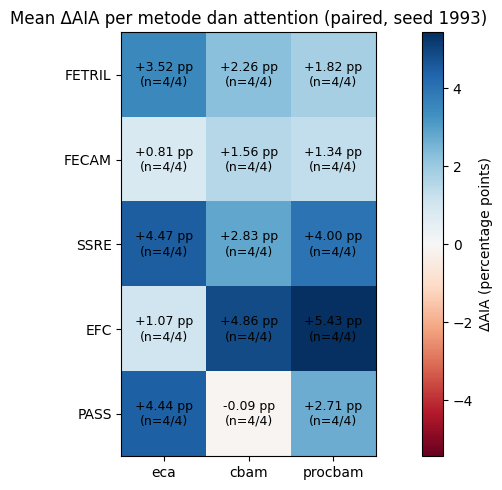

In [9]:
if gains.empty:
    print("Tidak ada gain untuk diplot.")
else:
    matrix = gains.pivot(index="method", columns="attention", values="mean_delta_aia")
    matrix = matrix.reindex(index=list(METHODS), columns=["eca", "cbam", "procbam"])
    counts = gains.pivot(index="method", columns="attention", values="n_pairs").reindex_like(matrix)
    fig, ax = plt.subplots(figsize=(10.5, 6))
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap="RdBu", vmin=-max(1, np.nanmax(np.abs(matrix.to_numpy(dtype=float)))), vmax=max(1, np.nanmax(np.abs(matrix.to_numpy(dtype=float)))))
    ax.set_xticks(range(3), matrix.columns, fontsize=13)
    ax.set_yticks(range(len(matrix.index)), [x.upper() for x in matrix.index], fontsize=13)
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            v = matrix.iat[i, j]
            if np.isfinite(v):
                n = counts.iat[i, j]
                ax.text(j, i, f"{v:+.2f} pp\n(n={int(n)}/4)", ha="center", va="center", fontsize=13)
    ax.set_title("Mean ΔAIA per metode dan attention (paired, seed 1993)", fontsize=15)
    cbar = fig.colorbar(image, ax=ax, label="ΔAIA (percentage points)")
    cbar.ax.yaxis.label.set_size(13)
    cbar.ax.tick_params(labelsize=12)
    fig.tight_layout()
    if GENERATE_FIGURES: fig.savefig(OUTPUT_DIR / "attention_gain_heatmap.png", dpi=170, bbox_inches="tight")
    plt.show()

## 8. Kurva joint accuracy per incremental task

Ubah pilihan berikut untuk membandingkan seluruh attention pada satu `dataset × method × protocol × backbone`. Perhatikan bahwa kurva T5 memiliki 5 titik, T10 memiliki 10 titik; sebaiknya **tidak ditumpuk pada satu axis tanpa penjelasan**.

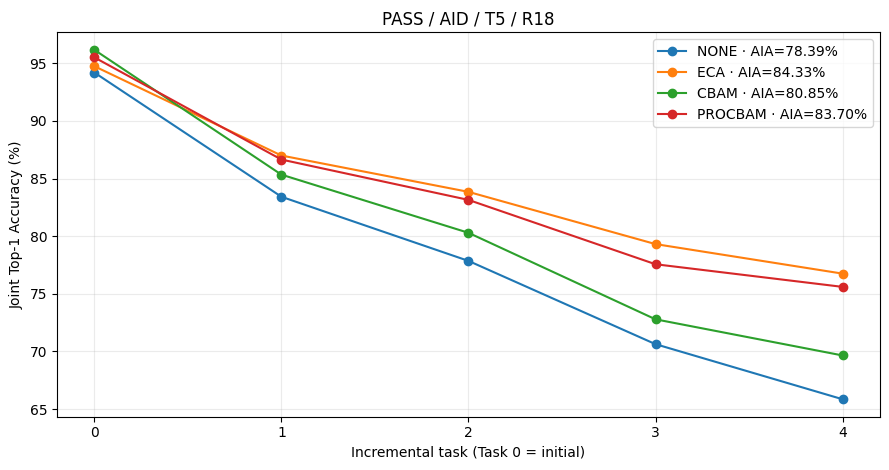

In [10]:
SELECT_DATASET = "aid"
SELECT_METHOD = "pass"        # fetril | fecam | ssre | efc | pass
SELECT_PROTOCOL = "T5"       # T5 | T10
SELECT_BACKBONE = "r18"      # r18 | r34

if valid.empty:
    print("Belum ada kurva valid.")
else:
    subset = valid[(valid.dataset == SELECT_DATASET) & (valid.method == SELECT_METHOD)
                   & (valid.protocol == SELECT_PROTOCOL) & (valid.backbone == SELECT_BACKBONE)]
    if subset.empty:
        print("Tidak ada kurva valid untuk kombinasi ini.")
    else:
        fig, ax = plt.subplots(figsize=(9, 4.8))
        for attention in ATTENTIONS:
            sample = subset[subset.attention == attention]
            if sample.empty: continue
            row = sample.iloc[0]
            curve = row.task_curve
            ax.plot(range(len(curve)), curve, marker="o", label=f"{attention.upper()} · AIA={row.aia:.2f}%")
        ax.set_xlabel("Incremental task (Task 0 = initial)")
        ax.set_ylabel("Joint Top-1 Accuracy (%)")
        ax.set_title(f"{SELECT_METHOD.upper()} / {SELECT_DATASET.upper()} / {SELECT_PROTOCOL} / {SELECT_BACKBONE.upper()}")
        ax.set_xticks(range(5 if SELECT_PROTOCOL == "T5" else 10))
        ax.grid(alpha=.25)
        ax.legend(loc="best")
        fig.tight_layout()
        if GENERATE_FIGURES:
            fig.savefig(OUTPUT_DIR / f"accuracy_curve_{SELECT_METHOD}_{SELECT_DATASET}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}.png", dpi=170)
        plt.show()

## 8B. Diagnostik forgetting dan old/new accuracy

Notebook menghitung ulang akurasi pada kelompok kelas yang sudah pernah dipelajari (*old*) dan kelompok kelas yang baru diperkenalkan pada task tersebut (*new*) dari confusion matrix masing-masing task. Ini berguna untuk mengamati stabilitas/plasticity pada PASS, EFC, dan metode lain.

Berikut juga ditampilkan heatmap **akurasi setiap kelompok task setelah tahap training** dan perbandingan Forgetting Rate/BWT yang direkonstruksi dengan nilai yang disimpan oleh runner. Jika angka berbeda, **hasil runner tetap menjadi metrik pelaporan utama** sampai penyebab perbedaan skala/definisi dikonfirmasi.

**PASS / T5 / R18 / NONE**

,task_id,seen_classes,old_accuracy_pct,new_accuracy_pct,joint_accuracy_pct
0,0,14,NaN,94.20,94.20
1,1,18,81.40,91.38,83.42
2,2,22,74.96,89.31,77.86
3,3,26,66.43,92.14,70.63
4,4,30,60.43,98.59,65.85


FR stored: 28.413019076808148; computed from class histories: 28.413 (periksa skala/definisi bila berbeda)
BWT stored: -27.215953800217733; computed from grouped task accuracies: -27.216 (periksa skala/definisi bila berbeda)


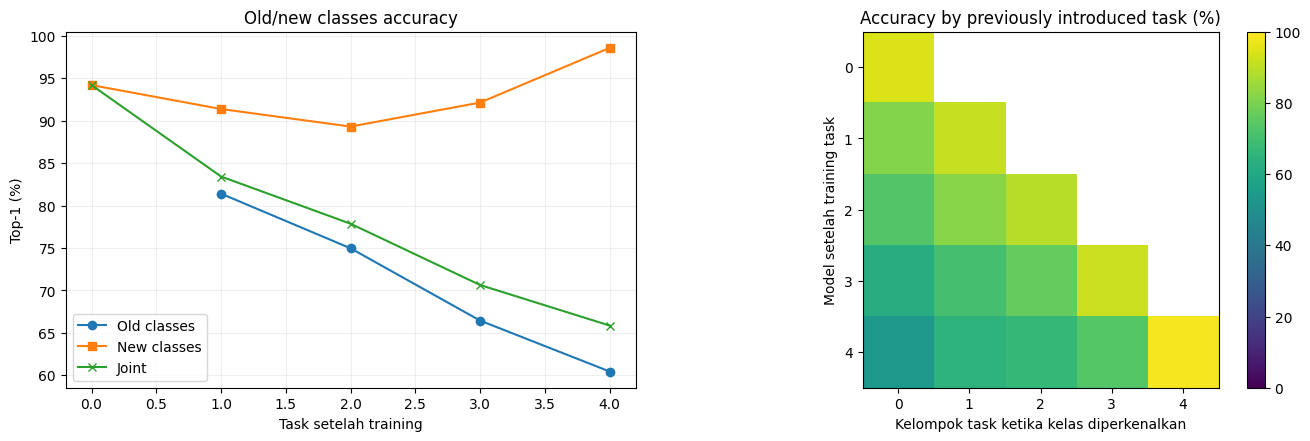

In [11]:
def task_group_diagnostics(row):
    run_dir = Path(row.run_dir)
    seen = list(row.seen_classes_curve)
    starts = [0] + seen[:-1]
    n_tasks, total_classes = len(seen), seen[-1]
    per_class = np.full((n_tasks, total_classes), np.nan)
    per_task = np.full((n_tasks, n_tasks), np.nan)
    grouped_rows = []
    for t in range(n_tasks):
        cm = np.load(run_dir / "confusion_matrices" / f"task_{t:02d}.npy", allow_pickle=False)
        diag, counts = np.diag(cm), cm.sum(axis=1)
        per_class[t, :seen[t]] = np.divide(diag, counts, out=np.zeros_like(diag, dtype=float), where=counts>0) * 100
        for j in range(t+1):
            start, end = starts[j], seen[j]
            per_task[t,j] = float(diag[start:end].sum() / counts[start:end].sum() * 100) if counts[start:end].sum() else np.nan
        old_end = starts[t]
        old = (float(diag[:old_end].sum() / counts[:old_end].sum() * 100)
               if old_end and counts[:old_end].sum() else np.nan)
        new = (float(diag[old_end:seen[t]].sum() / counts[old_end:seen[t]].sum() * 100)
               if counts[old_end:seen[t]].sum() else np.nan)
        grouped_rows.append({"task_id":t, "seen_classes":seen[t], "old_accuracy_pct":old,
                             "new_accuracy_pct":new, "joint_accuracy_pct":float(row.task_curve[t])})
    forgetting = np.nanmax(per_class, axis=0) - per_class[-1]
    fr_recomputed = float(np.nanmean(forgetting))
    bwt_recomputed = float(np.nanmean(per_task[-1,:-1] - np.diag(per_task)[:-1]))
    return pd.DataFrame(grouped_rows), per_task, per_class, forgetting, fr_recomputed, bwt_recomputed

if valid.empty:
    print("Belum ada hasil untuk diagnostik old/new.")
else:
    chosen = valid[(valid.dataset==SELECT_DATASET)&(valid.method==SELECT_METHOD)&
                   (valid.protocol==SELECT_PROTOCOL)&(valid.backbone==SELECT_BACKBONE)&
                   (valid.attention=="none")]
    if chosen.empty:
        chosen = valid[(valid.dataset==SELECT_DATASET)&(valid.method==SELECT_METHOD)&
                       (valid.protocol==SELECT_PROTOCOL)&(valid.backbone==SELECT_BACKBONE)]
    if chosen.empty:
        print("Konfigurasi diagnostik yang dipilih belum tersedia.")
    else:
        r = chosen.iloc[0]
        groups, task_matrix, class_matrix, class_forgetting, fr_calc, bwt_calc = task_group_diagnostics(r)
        display(Markdown(f"**{r.method.upper()} / {r.protocol} / {r.backbone.upper()} / {r.attention.upper()}**"))
        display(groups.round(2))
        print(f"FR stored: {r.fr}; computed from class histories: {fr_calc:.3f} (periksa skala/definisi bila berbeda)")
        print(f"BWT stored: {r.bwt}; computed from grouped task accuracies: {bwt_calc:.3f} (periksa skala/definisi bila berbeda)")
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), constrained_layout=True)
        axes[0].plot(groups.task_id, groups.old_accuracy_pct, marker='o', label='Old classes')
        axes[0].plot(groups.task_id, groups.new_accuracy_pct, marker='s', label='New classes')
        axes[0].plot(groups.task_id, groups.joint_accuracy_pct, marker='x', label='Joint')
        axes[0].set_xlabel('Task setelah training'); axes[0].set_ylabel('Top-1 (%)')
        axes[0].set_title('Old/new classes accuracy'); axes[0].legend(); axes[0].grid(alpha=.2)
        im=axes[1].imshow(task_matrix, vmin=0, vmax=100, cmap='viridis')
        axes[1].set_xlabel('Kelompok task ketika kelas diperkenalkan', fontsize=13)
        axes[1].set_ylabel('Model setelah training task', fontsize=13)
        axes[1].set_title('Accuracy by previously introduced task (%)', fontsize=14)
        axes[1].tick_params(axis='both', labelsize=12)
        cbar = fig.colorbar(im, ax=axes[1])
        cbar.ax.tick_params(labelsize=12)
        plt.show()
        name=f"diagnostics_{r.method}_{r.protocol}_{r.backbone}_{r.attention}"
        groups.to_csv(OUTPUT_DIR/f"{name}_old_new.csv",index=False)
        pd.DataFrame(task_matrix).to_csv(OUTPUT_DIR/f"{name}_task_matrix.csv",index=False)


## 9. Confusion matrix akhir: baseline vs attention

Confusion matrix berasal dari prediksi canonical di **task terakhir**. Nilai heatmap ditampilkan **row-normalized (%)**, sehingga kelas AID yang jumlah citranya tidak seimbang tetap dapat dibandingkan secara adil dalam interpretasi *recall per class*. Detail kelas ditampilkan sebagai ID incremental `C00`, `C01`, dan seterusnya jika nama kelas asli tidak tersedia.

**Label kelas:** jangan mengasumsikan ID incremental sama dengan alphabetical original class ID. Jika sudah memiliki manifest `incremental_id → class_name` dari split seed 1993, isi `CLASS_LABELS` di bawah.

Baseline, attention, dan selisih ditampilkan sebagai **tiga gambar terpisah**, masing-masing diekspor ke PNG 300 dpi dan PDF agar label kelas terbaca di naskah.


In [12]:
# Opsional: label yang BENAR berdasarkan mapping incremental class order yang dipakai.
# Contoh format: {"aid": {0: "nama_kelas_pertama", 1: "nama_kelas_kedua"}}
CLASS_LABELS = {}
COMPARE_ATTENTION = "procbam"  # eca | cbam | procbam


def fetch_cm(valid_runs, dataset, method, protocol, backbone, attention):
    required = {"dataset", "method", "protocol", "backbone", "attention", "run_dir"}
    if valid_runs is None or valid_runs.empty or not required.issubset(valid_runs.columns):
        return None, None
    subset = valid_runs[(valid_runs["dataset"] == dataset) & (valid_runs["method"] == method)
                        & (valid_runs["protocol"] == protocol) & (valid_runs["backbone"] == backbone)
                        & (valid_runs["attention"] == attention)]
    if len(subset) != 1:
        return None, None
    row = subset.iloc[0]
    cm_path = Path(row.run_dir) / "final_confusion_matrix.npy"
    if not cm_path.exists():
        return None, None
    cm = np.load(cm_path, allow_pickle=False)
    return row, cm


def normalize_rows(cm):
    cm = np.asarray(cm, dtype=float)
    return np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm), where=cm.sum(axis=1, keepdims=True)>0) * 100

row_none, cm_none = (None, None)
row_attn, cm_attn = (None, None)
if not valid.empty:
    row_none, cm_none = fetch_cm(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, "none")
    row_attn, cm_attn = fetch_cm(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, COMPARE_ATTENTION)

if cm_none is None or cm_attn is None:
    print("Baseline atau attention yang dipilih belum memiliki confusion matrix final valid.")

In [ ]:
if cm_none is not None and cm_attn is not None:
    if cm_none.shape != cm_attn.shape or not np.array_equal(cm_none.sum(axis=1), cm_attn.sum(axis=1)):
        print("STOP: jumlah kelas atau true-label histogram berbeda; belum boleh membandingkan confusion matrix.")
    else:
        labels = [CLASS_LABELS.get(SELECT_DATASET, {}).get(i, f"C{i:02d}") for i in range(cm_none.shape[0])]
        before, after = normalize_rows(cm_none), normalize_rows(cm_attn)
        diff = after - before
        specs = [
            ("none", before, "Baseline (None) · recall distribution %", "Blues", (0, 100)),
            (COMPARE_ATTENTION, after, f"{COMPARE_ATTENTION.upper()} · recall distribution %", "Blues", (0, 100)),
            ("delta", diff, "Attention − None (pp)", "RdBu_r", (-max(1, np.abs(diff).max()), max(1, np.abs(diff).max()))),
        ]
        for panel, arr, title, cmap, scale in specs:
            fig, ax = plt.subplots(figsize=(10, 10.5), constrained_layout=True)
            im = ax.imshow(arr, cmap=cmap, vmin=scale[0], vmax=scale[1], interpolation="nearest")
            ax.set_title(f"{SELECT_METHOD.upper()} / {SELECT_BACKBONE.upper()} / {SELECT_PROTOCOL}\n{title}", fontsize=15)
            ax.set_xlabel("Predicted incremental class", fontsize=14)
            ax.set_ylabel("True incremental class", fontsize=14)
            if len(labels) <= 45:
                ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=12)
                ax.set_yticks(range(len(labels)), labels, fontsize=12)
            cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03, label="Change (pp)" if panel == "delta" else "Within true-class row (%)")
            cbar.ax.yaxis.label.set_size(13)
            cbar.ax.tick_params(labelsize=12)
            if GENERATE_FIGURES:
                destination = OUTPUT_DIR / f"confusion_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}_{panel}.png"
                fig.savefig(destination, dpi=300, bbox_inches="tight")
                fig.savefig(destination.with_suffix(".pdf"), bbox_inches="tight")
            plt.show()

        # Recall per class / kelompok kelas yang paling meningkat atau menurun.
        delta_recall = np.diag(diff)
        class_table = pd.DataFrame({"incremental_id": range(len(labels)), "class_name": labels,
                                    "recall_none_pct": np.diag(before),
                                    "recall_attention_pct": np.diag(after),
                                    "delta_recall_pp": delta_recall})
        print("Top 10 perbaikan recall kelas:")
        display(class_table.nlargest(10, "delta_recall_pp").round(2))
        print("Top 10 penurunan recall kelas:")
        display(class_table.nsmallest(10, "delta_recall_pp").round(2))
        class_table.to_csv(OUTPUT_DIR / f"class_recall_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False)

        # High inter-class similarity: pasangan label keliru yang paling berkurang.
        pair_changes = []
        for i in range(cm_none.shape[0]):
            for j in range(cm_none.shape[1]):
                if i == j: continue
                pair_changes.append({"true_id": i, "pred_id": j, "true_class": labels[i],
                                    "pred_class": labels[j], "count_none": int(cm_none[i,j]),
                                    "count_attn": int(cm_attn[i,j]),
                                    "decrease_in_errors": int(cm_none[i,j] - cm_attn[i,j]),
                                    "decrease_error_rate_pp": float(before[i,j] - after[i,j])})
        changes_df = pd.DataFrame(pair_changes)
        print("Top 12 arah misclassification yang paling berkurang (perhatikan error baru yang bertambah):")
        display(changes_df.nlargest(12, "decrease_in_errors").round(2))
        changes_df.to_csv(OUTPUT_DIR / f"confusion_pair_changes_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False)

## 10. Ekspor tabel & ringkasan readiness

Notebook menyimpan laporan audit meskipun belum semua run lengkap. Hanya baris `eligible = True` digunakan dalam analisis. File CSV/JSON tetap dapat digunakan di Excel/Google Sheets atau untuk menulis Bab IV.

Catatan: **jangan gunakan grafik / ranking sementara untuk klaim akhir** sebelum pasangan baseline-vs-attention lengkap serta seluruh konflik diselesaikan. Pastikan klasifikasi hasil sesuai schema dan verifier `production_section.py` terkini.

In [14]:
def exportable(df):
    if df.empty: return df.copy()
    out = df.copy()
    for col in out.columns:
        if out[col].dtype == "object":
            out[col] = out[col].map(lambda v: json.dumps(v, ensure_ascii=False) if isinstance(v, (list, dict, tuple)) else v)
    return out

exports = {
    "run_audit.csv": runs,
    "valid_runs.csv": valid,
    "expected_coverage_aid.csv": coverage,
    "paired_attention_deltas.csv": paired,
    "rejected_unfair_pairs.csv": rejected_pairs,
    "attention_gain_summary.csv": gains,
}
for name, frame in exports.items():
    exportable(frame).to_csv(OUTPUT_DIR / name, index=False, encoding="utf-8-sig")

final_state = {
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "expected_aid_runs": int(len(coverage)),
    "valid_aid_runs": int(coverage["coverage"].str.startswith("ready").sum()),
    "run_candidates": int(len(runs)),
    "valid_in_scope": int(len(valid)),
    "paired_attention_comparisons": int(len(paired)),
    "rejected_unfair_pairs": int(len(rejected_pairs)),
    "duplicate_conflicts": int((runs["status"] == "duplicate_conflict").sum()) if not runs.empty else 0,
    "scope": DATASET_SCOPE,
    "single_training_seed": EXPECTED_SEED,
    "fwt": "not applicable under dynamic classifier protocol",
    "note": "Checkpoint inventory is source-only structural evidence, not proof of torch.load success.",
}
(OUTPUT_DIR / "analysis_status.json").write_text(json.dumps(final_state, indent=2), encoding="utf-8")
print(json.dumps(final_state, indent=2))
print("\nTabel dan gambar tersimpan di:", OUTPUT_DIR)

{
  "generated_at": "2026-11-12T16:01:49",
  "expected_aid_runs": 80,
  "valid_aid_runs": 80,
  "run_candidates": 80,
  "valid_in_scope": 80,
  "paired_attention_comparisons": 60,
  "rejected_unfair_pairs": 0,
  "duplicate_conflicts": 0,
  "scope": "aid",
  "single_training_seed": 1993,
  "fwt": "not applicable under dynamic classifier protocol",
  "note": "Checkpoint inventory is source-only structural evidence, not proof of torch.load success."
}

Tabel dan gambar tersimpan di: C:\Skripsi\Project\PyCIL\outputs\analysis


## 11. Kriteria siap untuk pembahasan Bab IV

1. **Coverage:** 80/80 AID run pada grid final jika semua lima metode dimasukkan. Jangan menyamakan target AID 80 run dengan proposal awal dua dataset (160 konfigurasi).
2. **Completeness:** masing-masing run mempunyai prediksi dan confusion matrix **setiap task**, `summary.json`, `continual_metrics.json`, config/provenance, serta checkpoint+method-state+manifest. Hasil `ready_snapshot` sebaiknya diverifikasi penuh di mesin sumber.
3. **Fairness:** keempat attention satu bundle memiliki metode, dataset, task order, seed, backbone, batch, dan hardware identik.
4. **Evaluasi utama:** nilai AIA dan LTA per run; ΔAIA/ΔLTA terhadap `none` pada paired bundle; Mean ΔAIA per metode/attention (laporkan `n_pairs`).
5. **Evaluasi tambahan:** Macro-F1, FR, BWT, kurva akurasi; analisis confusion pair pada kombinasi paling meningkat / paling menurun. FWT `not applicable` dan bukan nol.
6. **Interpretasi:** peningkatan paling besar secara deskriptif, **bukan signifikan secara statistik** ketika hanya seed 1993 yang digunakan.
7. **Dokumentasi:** simpan versi kode/commit, konfigurasi, sumber komputer, audit, hasil CSV dan gambar yang digunakan pada pembahasan.

*Notebook ini dibuat berdasarkan kontrak file runner/production section yang tersedia dalam konteks skripsi. Jika schema actual `config.json`, `continual_metrics.json`, atau `task_metrics.json` sudah berubah, tampilkan tabel audit untuk mengidentifikasi field yang harus disesuaikan sebelum melakukan analisis akhir.*

**Schema check:** nama metrik `paired` dari sel lama berbeda dengan nama yang dipakai laporan Bab IV (`delta_aia` versus `delta_aia_pp`). Versi ini menormalisasi keduanya. **Restart Kernel → Run All** supaya hasil lama di RAM tidak tercampur dengan versi notebook baru.

## 10B. Tabel Bab IV — perbandingan AIA dan LTA serta ΔAIA/ΔLTA

Tabel 4.1–4.4 adalah nilai AIA/LTA absolut pada T5 dan T10. **Sejalan dengan rancangan Bab IV di buku**, tabel **4.5 = ΔAIA dan ΔLTA pada T5** (30 pasangan), tabel **4.6 = ΔAIA dan ΔLTA pada T10** (30 pasangan). Semua 60 pasangan juga diekspor dalam format panjang (*long format*) untuk penelusuran ke `run_id` dan perbandingan AI.

Notebook menerima nama metrik dari runner `delta_aia`, `delta_lta`, `aia_none`, dan `aia_attention`, lalu menambahkan alias `*_pp` dan `*_pct` secara eksplisit. Nilai tidak ditaksir atau diisi nol jika eksperimen belum lengkap.


In [15]:
def method_backbone_rows():
    return [f"{METHOD_LABELS[m]} / {b.upper()}" for m in METHODS for b in BACKBONES]


def build_main_metric_table(valid_runs: pd.DataFrame, protocol: str, metric_col: str, metric_label: str):
    cols = ["none", "eca", "cbam", "procbam"]
    if valid_runs.empty:
        return pd.DataFrame(columns=["method", "backbone"] + [ATTN_LABELS[c] for c in cols])
    sub = valid_runs[(valid_runs.dataset == DATASET_SCOPE) & (valid_runs.protocol == protocol)].copy()
    sub["method"] = pd.Categorical(sub["method"], METHODS, ordered=True)
    sub["backbone"] = pd.Categorical(sub["backbone"], BACKBONES, ordered=True)
    sub["row"] = sub["method"].astype(str).map(METHOD_LABELS).fillna(sub["method"].astype(str)) + " / " + sub["backbone"].astype(str).str.upper()
    piv = sub.pivot_table(index="row", columns="attention", values=metric_col, aggfunc="first")
    piv = piv.reindex(index=method_backbone_rows(), columns=cols)
    out = piv.rename(columns=ATTN_LABELS).reset_index().rename(columns={"row": "method_backbone"})
    out.insert(0, "protocol", protocol)
    out.insert(1, "metric", metric_label)
    return out


def build_pair_delta_table(pairs: pd.DataFrame, protocol: str) -> pd.DataFrame:
    """Bab IV tables 4.5/4.6: 10 method/backbone rows × (ΔAIA, ΔLTA for 3 attentions)."""
    expected = [(m, b) for m in METHODS for b in BACKBONES]
    cols = ["method", "backbone"]
    for attn in PAIR_ATTENTIONS:
        cols += [f"delta_aia_{attn}_pp", f"delta_lta_{attn}_pp"]
    pair_data = normalize_pair_schema(pairs)
    sub = pair_data[pair_data["protocol"] == protocol].copy()
    records = []
    for method, backbone in expected:
        rec = {"method": METHOD_LABELS[method], "backbone": f"ResNet-{backbone[1:]}"}
        for attn in PAIR_ATTENTIONS:
            subpair = sub[(sub["method"] == method) & (sub["backbone"] == backbone) &
                          (sub["attention"] == attn)]
            if len(subpair) > 1:
                raise ValueError(f"Duplicate pair {method} {backbone} {protocol} {attn}; tidak boleh memilih diam-diam")
            rec[f"delta_aia_{attn}_pp"] = float(subpair.iloc[0]["delta_aia_pp"]) if len(subpair) else np.nan
            rec[f"delta_lta_{attn}_pp"] = float(subpair.iloc[0]["delta_lta_pp"]) if len(subpair) else np.nan
        records.append(rec)
    return pd.DataFrame(records, columns=cols)


def sorted_pair_details(pairs: pd.DataFrame) -> pd.DataFrame:
    """Seluruh 60 pair + metadata dan nilai baseline/attention untuk cross-check."""
    out = normalize_pair_schema(pairs)
    if out.empty:
        return out
    out = out.copy()
    for col, order in (("method", METHODS), ("protocol", PROTOCOLS),
                       ("backbone", BACKBONES), ("attention", PAIR_ATTENTIONS)):
        out[col] = pd.Categorical(out[col], categories=order, ordered=True)
    return out.sort_values(["protocol", "method", "backbone", "attention"]).reset_index(drop=True)


tbl_41 = build_main_metric_table(valid, "T5", "aia", "AIA")
tbl_42 = build_main_metric_table(valid, "T5", "lta", "LTA")
tbl_43 = build_main_metric_table(valid, "T10", "aia", "AIA")
tbl_44 = build_main_metric_table(valid, "T10", "lta", "LTA")
tbl_45 = build_pair_delta_table(paired, "T5")
tbl_46 = build_pair_delta_table(paired, "T10")
all_pair_details = sorted_pair_details(paired)

print("Tabel 4.1 — AIA T5")
display(tbl_41.round(2))
print("Tabel 4.2 — LTA T5")
display(tbl_42.round(2))
print("Tabel 4.3 — AIA T10")
display(tbl_43.round(2))
print("Tabel 4.4 — LTA T10")
display(tbl_44.round(2))
print("Tabel 4.5 — ΔAIA / ΔLTA vs None, T5 (30 pasangan)")
display(tbl_45.round(2))
print("Tabel 4.6 — ΔAIA / ΔLTA vs None, T10 (30 pasangan)")
display(tbl_46.round(2))

if not all_pair_details.empty:
    expected_pairs_in_scope = len(METHODS) * len(BACKBONES) * len(PROTOCOLS) * len(PAIR_ATTENTIONS)
    print(f"Fair paired attention comparisons: {len(all_pair_details)}/{expected_pairs_in_scope}")
    if len(valid) == len(METHODS) * len(BACKBONES) * len(PROTOCOLS) * len(ATTENTIONS):
        assert len(all_pair_details) == expected_pairs_in_scope, (
            "Seluruh 80 model ditemukan tetapi belum semua pasangan fair: periksa rejected_pairs."
        )
    check = all_pair_details[["dataset", "method", "protocol", "backbone", "seed", "attention",
                              "source_machine", "batch", "baseline_run_id", "attention_run_id",
                              "baseline_aia_pct", "attention_aia_pct", "delta_aia_pp",
                              "baseline_lta_pct", "attention_lta_pct", "delta_lta_pp",
                              "delta_fr_pp", "delta_bwt_pp"]]
    display(check.round(3))

main_tables = {
    "table_4_1_aia_t5.csv": tbl_41,
    "table_4_2_lta_t5.csv": tbl_42,
    "table_4_3_aia_t10.csv": tbl_43,
    "table_4_4_lta_t10.csv": tbl_44,
    "table_4_5_delta_aia_lta_t5.csv": tbl_45,
    "table_4_6_delta_aia_lta_t10.csv": tbl_46,
    "paired_attention_full_details_all.csv": all_pair_details,
}
for name, frame in main_tables.items():
    exportable(frame).to_csv(TABLE_DIR / name, index=False, encoding="utf-8-sig")

# Excel workbook: satu tab per tabel Bab IV + satu tab seluruh 60 pasangan.
try:
    with pd.ExcelWriter(TABLE_DIR / "bab4_main_tables.xlsx") as xw:
        for filename, frame in main_tables.items():
            sheet = {
                "table_4_1_aia_t5.csv": "4.1_AIA_T5",
                "table_4_2_lta_t5.csv": "4.2_LTA_T5",
                "table_4_3_aia_t10.csv": "4.3_AIA_T10",
                "table_4_4_lta_t10.csv": "4.4_LTA_T10",
                "table_4_5_delta_aia_lta_t5.csv": "4.5_delta_T5",
                "table_4_6_delta_aia_lta_t10.csv": "4.6_delta_T10",
                "paired_attention_full_details_all.csv": "60_pairs_full",
            }[filename]
            exportable(frame).to_excel(xw, sheet_name=sheet, index=False)
    print("Workbook utama tersimpan:", TABLE_DIR / "bab4_main_tables.xlsx")
except Exception as exc:
    print("Workbook Excel tidak dibuat:", exc)


Tabel 4.1 — AIA T5


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T5,AIA,FeTrIL / R18,85.11,87.81,86.50,85.67
1,T5,AIA,FeTrIL / R34,84.41,86.13,87.63,85.88
2,T5,AIA,FeCAM / R18,87.66,86.94,88.37,88.32
3,T5,AIA,FeCAM / R34,83.01,84.97,84.95,84.15
4,T5,AIA,SSRE / R18,78.82,82.35,80.50,82.11
5,T5,AIA,SSRE / R34,77.68,80.83,79.65,80.28
6,T5,AIA,EFC / R18,76.88,78.36,81.45,82.39
7,T5,AIA,EFC / R34,76.01,77.38,79.71,80.08
8,T5,AIA,PASS / R18,78.39,84.33,80.85,83.70
9,T5,AIA,PASS / R34,81.24,82.33,80.93,82.87


Tabel 4.2 — LTA T5


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T5,LTA,FeTrIL / R18,77.80,81.45,78.75,77.50
1,T5,LTA,FeTrIL / R34,76.05,78.30,80.70,78.50
2,T5,LTA,FeCAM / R18,81.45,80.80,83.10,82.45
3,T5,LTA,FeCAM / R34,75.45,78.40,77.90,77.20
4,T5,LTA,SSRE / R18,69.85,74.20,71.65,73.25
5,T5,LTA,SSRE / R34,69.15,73.80,70.55,72.20
6,T5,LTA,EFC / R18,71.35,73.75,76.90,78.50
7,T5,LTA,EFC / R34,70.90,72.90,75.00,75.45
8,T5,LTA,PASS / R18,65.85,76.75,69.65,75.60
9,T5,LTA,PASS / R34,74.90,76.25,74.00,76.55


Tabel 4.3 — AIA T10


attention,protocol,metric,method_backbone,None,ECA,CBAM,ProCBAM
0,T10,AIA,FeTrIL / R18,78.26,82.61,81.32,81.49
1,T10,AIA,FeTrIL / R34,78.80,84.10,80.16,80.80
2,T10,AIA,FeCAM / R18,83.16,83.41,85.39,85.83
3,T10,AIA,FeCAM / R34,77.59,79.34,78.95,78.48
4,T10,AIA,SSRE / R18,71.79,77.60,74.43,76.00
5,T10,AIA,SSRE / R34,69.87,75.27,74.90,75.76
6,T10,AIA,EFC / R18,69.86,70.64,76.62,76.04
7,T10,AIA,EFC / R34,69.58,70.21,74.00,75.52
8,T10,AIA,PASS / R18,67.16,74.60,64.44,68.92
9,T10,AIA,PASS / R34,70.38,73.66,70.60,72.51


... (5 outputs left out)

,method,backbone,delta_aia_eca_pp,delta_lta_eca_pp,delta_aia_cbam_pp,delta_lta_cbam_pp,delta_aia_procbam_pp,delta_lta_procbam_pp
0,FeTrIL,ResNet-18,4.35,7.15,3.06,5.45,3.23,4.60
1,FeTrIL,ResNet-34,5.31,7.60,1.37,1.45,2.00,2.35
2,FeCAM,ResNet-18,0.25,-0.10,2.22,3.05,2.66,3.70
3,FeCAM,ResNet-34,1.75,2.60,1.36,2.20,0.89,2.75
4,SSRE,ResNet-18,5.81,8.65,2.64,4.45,4.20,6.05
5,SSRE,ResNet-34,5.40,7.35,5.03,3.80,5.89,4.70
6,EFC,ResNet-18,0.78,1.50,6.76,7.10,6.19,8.25
7,EFC,ResNet-34,0.64,1.20,4.43,4.95,5.95,6.10
8,PASS,ResNet-18,7.44,9.30,-2.72,-10.20,1.76,-3.70
9,PASS,ResNet-34,3.28,2.90,0.23,-4.65,2.13,-0.75


Fair paired attention comparisons: 60/60


,dataset,method,protocol,backbone,seed,attention,source_machine,batch,baseline_run_id,attention_run_id,baseline_aia_pct,attention_aia_pct,delta_aia_pp,baseline_lta_pct,attention_lta_pct,delta_lta_pp,delta_fr_pp,delta_bwt_pp
0,aid,fetril,T5,r18,1993,eca,server,32,aid_fetril_t5_r18_none_seed1993,aid_fetril_t5_r18_eca_seed1993,85.112,87.810,2.698,77.80,81.45,3.65,-4.314,4.753
1,aid,fetril,T5,r18,1993,cbam,server,32,aid_fetril_t5_r18_none_seed1993,aid_fetril_t5_r18_cbam_seed1993,85.112,86.501,1.389,77.80,78.75,0.95,-0.807,0.448
2,aid,fetril,T5,r18,1993,procbam,server,32,aid_fetril_t5_r18_none_seed1993,aid_fetril_t5_r18_procbam_seed1993,85.112,85.673,0.560,77.80,77.50,-0.30,-0.304,-1.171
3,aid,fetril,T5,r34,1993,eca,server,32,aid_fetril_t5_r34_none_seed1993,aid_fetril_t5_r34_eca_seed1993,84.409,86.134,1.725,76.05,78.30,2.25,-1.751,0.952
4,aid,fetril,T5,r34,1993,cbam,server,32,aid_fetril_t5_r34_none_seed1993,aid_fetril_t5_r34_cbam_seed1993,84.409,87.629,3.220,76.05,80.70,4.65,-2.489,2.242
5,aid,fetril,T5,r34,1993,procbam,server,32,aid_fetril_t5_r34_none_seed1993,aid_fetril_t5_r34_procbam_seed1993,84.409,85.881,1.472,76.05,78.50,2.45,-0.973,0.625
6,aid,fecam,T5,r18,1993,eca,pc2,20,aid_fecam_t5_r18_none_seed1993,aid_fecam_t5_r18_eca_seed1993,87.658,86.944,-0.715,81.45,80.80,-0.65,0.156,-0.079
7,aid,fecam,T5,r18,1993,cbam,pc2,20,aid_fecam_t5_r18_none_seed1993,aid_fecam_t5_r18_cbam_seed1993,87.658,88.367,0.708,81.45,83.10,1.65,1.242,-0.372
8,aid,fecam,T5,r18,1993,procbam,pc2,20,aid_fecam_t5_r18_none_seed1993,aid_fecam_t5_r18_procbam_seed1993,87.658,88.323,0.665,81.45,82.45,1.00,0.934,-0.850
9,aid,fecam,T5,r34,1993,eca,server,64,aid_fecam_t5_r34_none_seed1993,aid_fecam_t5_r34_eca_seed1993,83.014,84.972,1.958,75.45,78.40,2.95,-2.163,1.902


Workbook Excel tidak dibuat: No module named 'openpyxl'


## 10C. Heatmap ΔAIA, ΔLTA, ΔFR, dan ΔBWT

Sesuai arahan Bab IV, efek attention divisualisasikan dengan heatmap agar pola peningkatan/penurunan cepat terlihat:

- **ΔAIA** dan **ΔLTA**: nilai positif = lebih baik dari baseline.
- **ΔFR**: nilai **negatif** = forgetting berkurang (lebih baik).
- **ΔBWT**: nilai lebih tinggi biasanya lebih baik / lebih tidak negatif.

Baris merepresentasikan **metode × backbone × protocol**, kolom merepresentasikan **ECA / CBAM / ProCBAM**.  

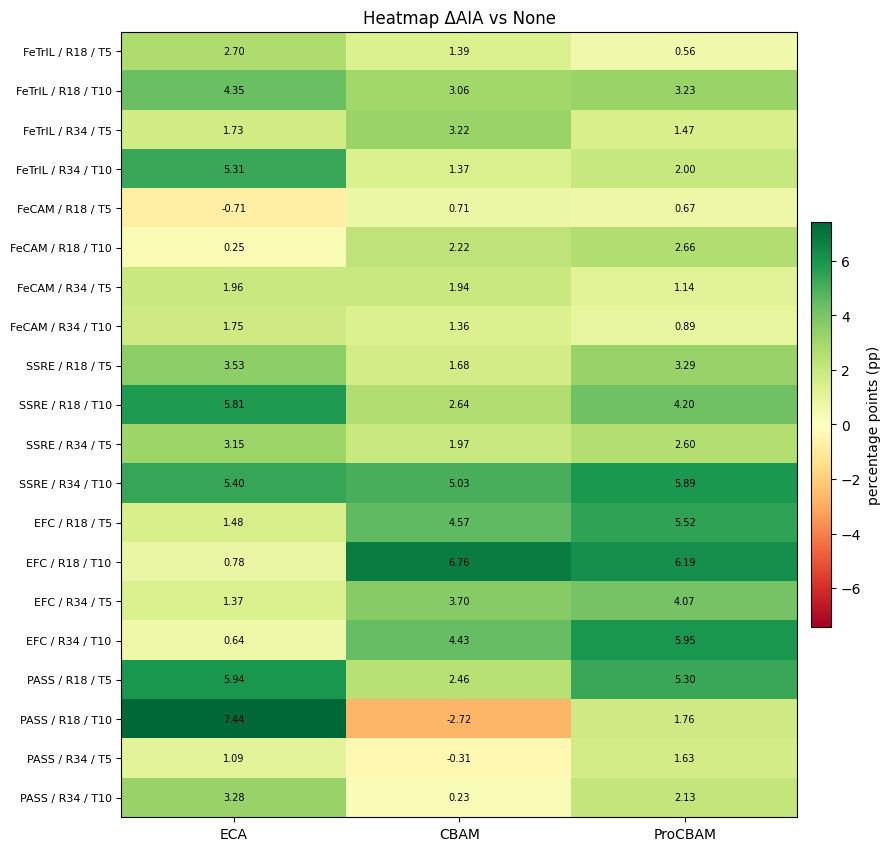

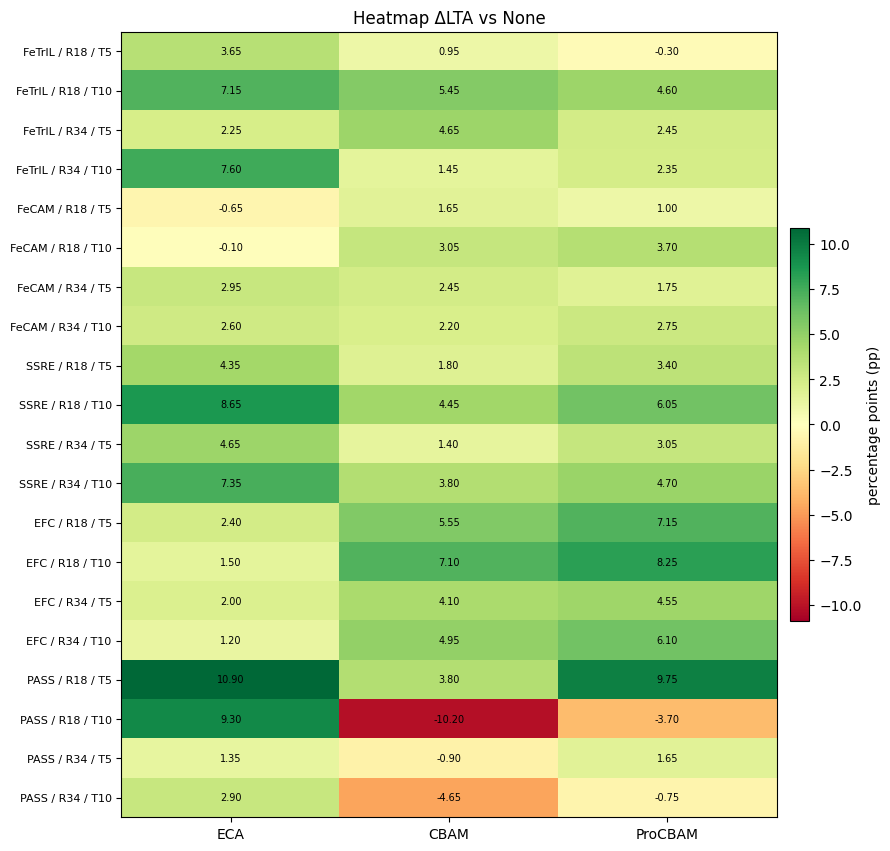

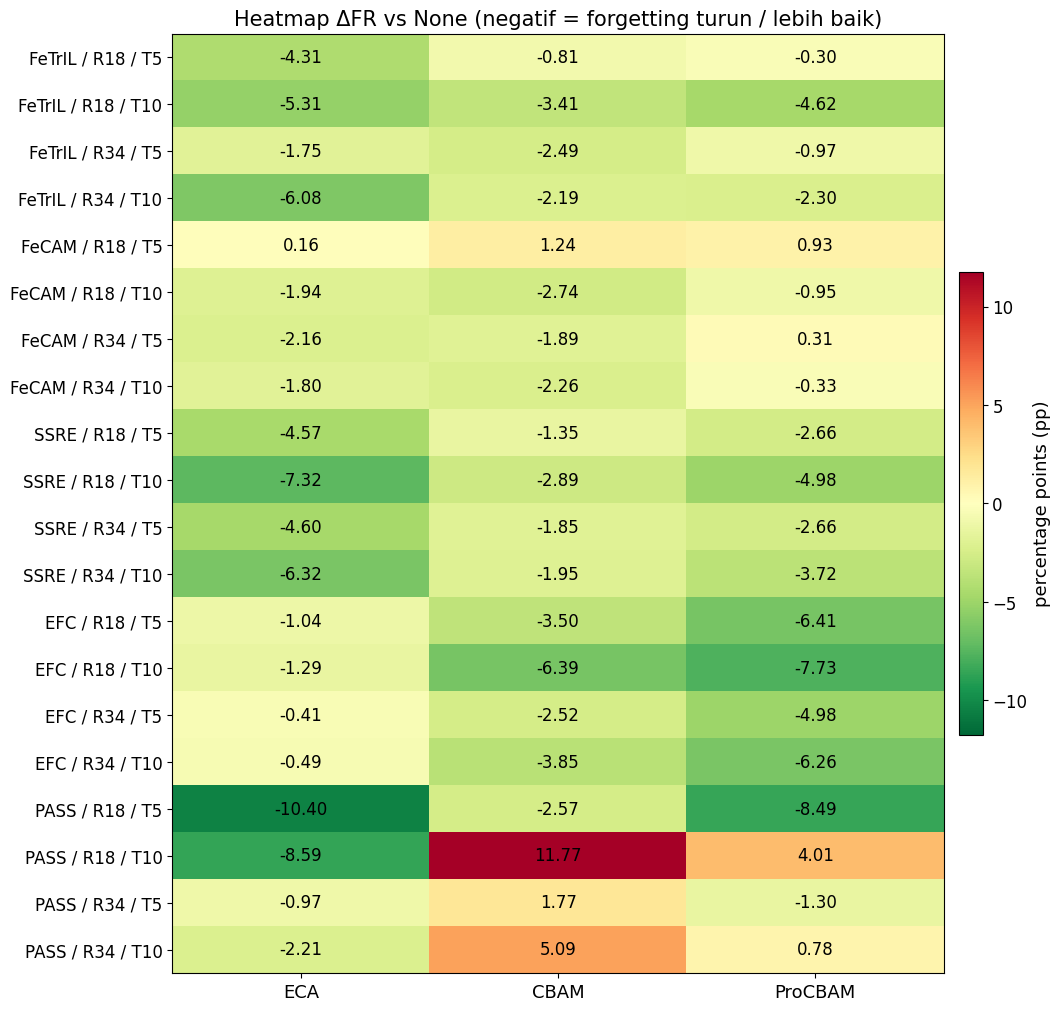

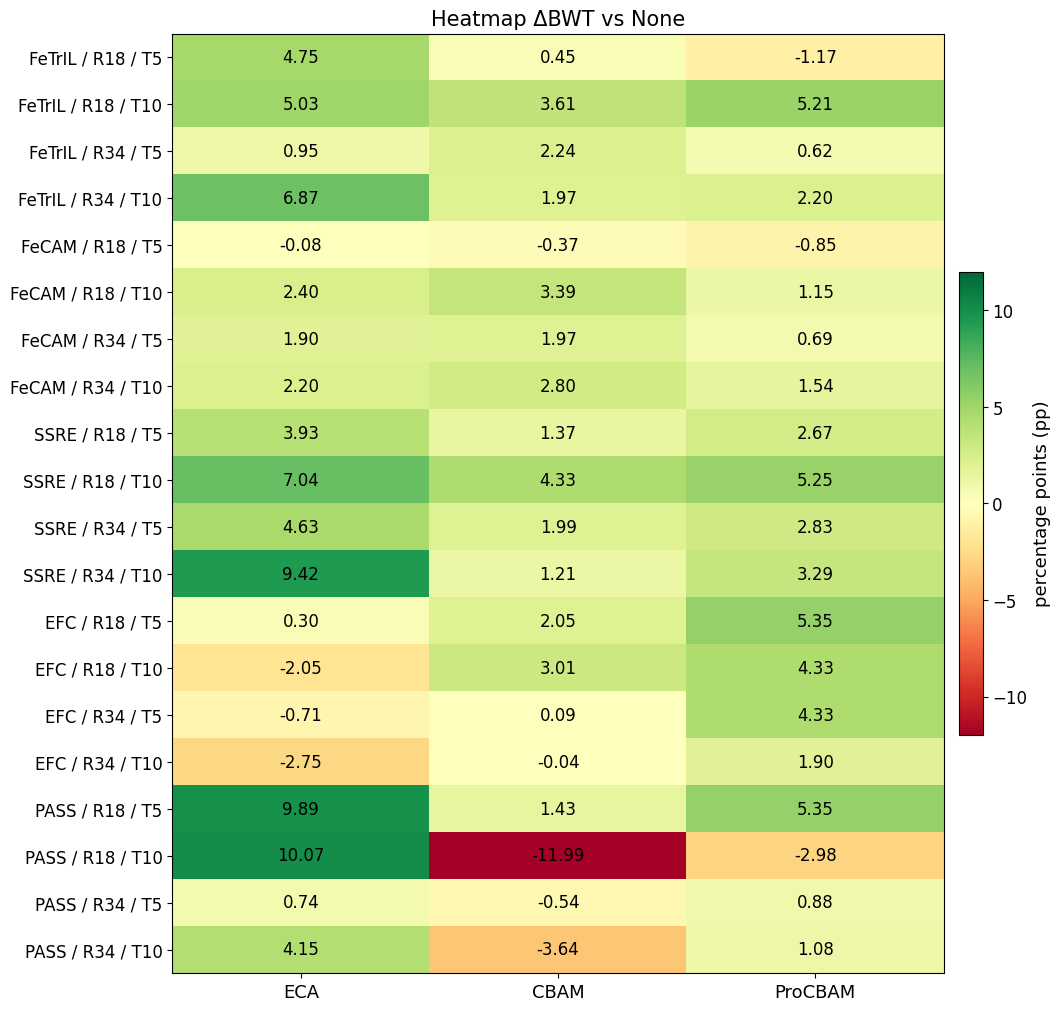

In [16]:
def build_delta_heatmap_matrix(pairs: pd.DataFrame, value_col: str):
    if pairs.empty:
        return pd.DataFrame()
    sub = normalize_pair_schema(pairs)
    if value_col not in sub.columns:
        raise ValueError(f"Kolom {value_col!r} belum tersedia; periksa schema paired di Cell 6.")
    sub["method"] = pd.Categorical(sub["method"], METHODS, ordered=True)
    sub["backbone"] = pd.Categorical(sub["backbone"], BACKBONES, ordered=True)
    sub["protocol"] = pd.Categorical(sub["protocol"], PROTOCOLS, ordered=True)
    sub["row"] = sub["method"].astype(str).map(METHOD_LABELS).fillna(sub["method"].astype(str)) + " / " + sub["backbone"].astype(str).str.upper() + " / " + sub["protocol"].astype(str)
    mat = sub.pivot_table(index="row", columns="attention", values=value_col, aggfunc="first")
    desired_rows = [f"{METHOD_LABELS[m]} / {b.upper()} / {p}" for m in METHODS for b in BACKBONES for p in PROTOCOLS]
    mat = mat.reindex(index=desired_rows, columns=list(PAIR_ATTENTIONS))
    return mat.rename(columns=ATTN_LABELS)


def plot_heatmap(df: pd.DataFrame, title: str, save_name: str, center: float = 0.0, note: str | None = None, smaller_is_better: bool = False, font_scale: float = 1.0):
    if df.empty:
        print(f"Heatmap '{title}' belum dapat dibuat karena data kosong.")
        return
    arr = df.to_numpy(dtype=float)
    finite = np.isfinite(arr)
    vmax = np.nanmax(np.abs(arr[finite])) if finite.any() else 1.0
    vmax = max(1.0, float(vmax))
    fig_h = max(7, 0.50 * len(df))
    fig, ax = plt.subplots(figsize=(10.5, fig_h), constrained_layout=True)
    im = ax.imshow(arr, cmap="RdYlGn_r" if smaller_is_better else "RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_title(title, fontsize=15 * font_scale)
    ax.set_xticks(range(df.shape[1]), df.columns, rotation=0, fontsize=13 * font_scale)
    ax.set_yticks(range(df.shape[0]), df.index, fontsize=12 * font_scale)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            val = df.iat[i, j]
            text = "" if pd.isna(val) else f"{val:.2f}"
            ax.text(j, i, text, ha="center", va="center", fontsize=12 * font_scale)
    cbar = fig.colorbar(im, ax=ax, fraction=0.030, pad=0.02)
    cbar.set_label("percentage points (pp)", fontsize=13 * font_scale)
    cbar.ax.tick_params(labelsize=12 * font_scale)
    if note:
        ax.set_xlabel(note, fontsize=13 * font_scale)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / save_name, dpi=180, bbox_inches="tight")
    plt.show()

heat_delta_aia = build_delta_heatmap_matrix(paired, "delta_aia_pp")
heat_delta_lta = build_delta_heatmap_matrix(paired, "delta_lta_pp")
heat_delta_fr = build_delta_heatmap_matrix(paired, "delta_fr_pp")
heat_delta_bwt = build_delta_heatmap_matrix(paired, "delta_bwt_pp")

# Simpan data sumber heatmap untuk keperluan cek manual.
exportable(heat_delta_aia.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_aia_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_lta.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_lta_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_fr.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_fr_source.csv", index=False, encoding="utf-8-sig")
exportable(heat_delta_bwt.reset_index()).to_csv(TABLE_DIR / "heatmap_delta_bwt_source.csv", index=False, encoding="utf-8-sig")

plot_heatmap(heat_delta_aia, "Heatmap ΔAIA vs None", "heatmap_delta_aia.png")
plot_heatmap(heat_delta_lta, "Heatmap ΔLTA vs None", "heatmap_delta_lta.png")
plot_heatmap(heat_delta_fr, "Heatmap ΔFR vs None (negatif = forgetting turun / lebih baik)", "heatmap_delta_fr.png", smaller_is_better=True)
plot_heatmap(heat_delta_bwt, "Heatmap ΔBWT vs None", "heatmap_delta_bwt.png")


## 10D. Grouped bar chart untuk *old* vs *new* accuracy

Visual ini membantu menjelaskan **stability vs plasticity**. Secara default, notebook membuat dua level analisis:

1. **Ringkasan bundle**: rata-rata `old-class accuracy` dan `new-class accuracy` pada seluruh task untuk `None`, `ECA`, `CBAM`, dan `ProCBAM` pada satu bundle terpilih.
2. **Tabel detail task-wise**: per task, `None` vs attention tertentu dapat dicross-check bila diperlukan.

Gunakan selector di bawah untuk memilih bundle yang ingin dimasukkan ke naskah.  

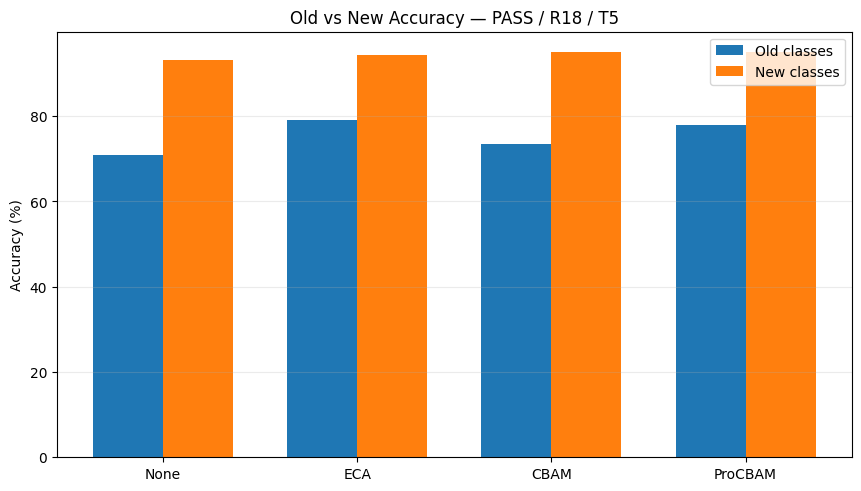

,dataset,method,protocol,backbone,attention,avg_old_accuracy_pct,avg_new_accuracy_pct,avg_joint_accuracy_pct,run_id
0,aid,pass,T5,r18,none,70.81,93.13,78.39,aid_pass_t5_r18_none_seed1993
1,aid,pass,T5,r18,eca,79.19,94.32,84.33,aid_pass_t5_r18_eca_seed1993
2,aid,pass,T5,r18,cbam,73.45,95.00,80.85,aid_pass_t5_r18_cbam_seed1993
3,aid,pass,T5,r18,procbam,77.89,95.04,83.70,aid_pass_t5_r18_procbam_seed1993


In [17]:
OLDNEW_DATASET = SELECT_DATASET
OLDNEW_METHOD = SELECT_METHOD
OLDNEW_PROTOCOL = SELECT_PROTOCOL
OLDNEW_BACKBONE = SELECT_BACKBONE


def get_run(valid_runs, dataset, method, protocol, backbone, attention):
    required = {"dataset", "method", "protocol", "backbone", "attention"}
    if valid_runs is None or valid_runs.empty or not required.issubset(valid_runs.columns):
        return None
    subset = valid_runs[(valid_runs["dataset"] == dataset) & (valid_runs["method"] == method) &
                        (valid_runs["protocol"] == protocol) & (valid_runs["backbone"] == backbone) &
                        (valid_runs["attention"] == attention)]
    return None if subset.empty else subset.iloc[0]


def summarize_bundle_old_new(valid_runs, dataset, method, protocol, backbone):
    rows = []
    taskwise_rows = []
    for attn in ATTENTIONS:
        run = get_run(valid_runs, dataset, method, protocol, backbone, attn)
        if run is None:
            continue
        groups, task_matrix, class_matrix, class_forgetting, fr_calc, bwt_calc = task_group_diagnostics(run)
        avg_old = groups["old_accuracy_pct"].dropna().mean() if "old_accuracy_pct" in groups else np.nan
        avg_new = groups["new_accuracy_pct"].dropna().mean() if "new_accuracy_pct" in groups else np.nan
        avg_joint = groups["joint_accuracy_pct"].dropna().mean() if "joint_accuracy_pct" in groups else np.nan
        rows.append({
            "dataset": dataset, "method": method, "protocol": protocol, "backbone": backbone,
            "attention": attn, "avg_old_accuracy_pct": avg_old, "avg_new_accuracy_pct": avg_new,
            "avg_joint_accuracy_pct": avg_joint, "run_id": run.run_id,
        })
        tmp = groups.copy()
        tmp.insert(0, "dataset", dataset)
        tmp.insert(1, "method", method)
        tmp.insert(2, "protocol", protocol)
        tmp.insert(3, "backbone", backbone)
        tmp.insert(4, "attention", attn)
        tmp.insert(5, "run_id", run.run_id)
        taskwise_rows.append(tmp)
    return pd.DataFrame(rows), (pd.concat(taskwise_rows, ignore_index=True) if taskwise_rows else pd.DataFrame())

bundle_oldnew, taskwise_oldnew = summarize_bundle_old_new(valid, OLDNEW_DATASET, OLDNEW_METHOD, OLDNEW_PROTOCOL, OLDNEW_BACKBONE)
if bundle_oldnew.empty:
    print("Belum ada data old/new accuracy untuk bundle yang dipilih.")
else:
    order = [a for a in ATTENTIONS if a in bundle_oldnew["attention"].tolist()]
    plot_df = bundle_oldnew.set_index("attention").reindex(order).reset_index()
    x = np.arange(len(plot_df))
    w = 0.36
    fig, ax = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
    ax.bar(x - w/2, plot_df["avg_old_accuracy_pct"], width=w, label="Old classes")
    ax.bar(x + w/2, plot_df["avg_new_accuracy_pct"], width=w, label="New classes")
    ax.set_xticks(x, [ATTN_LABELS[a] for a in plot_df["attention"]])
    ax.set_ylabel("Accuracy (%)")
    ax.set_title(f"Old vs New Accuracy — {METHOD_LABELS.get(OLDNEW_METHOD, OLDNEW_METHOD)} / {OLDNEW_BACKBONE.upper()} / {OLDNEW_PROTOCOL}")
    ax.legend()
    ax.grid(axis="y", alpha=.25)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / f"old_new_grouped_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.png", dpi=180, bbox_inches="tight")
    plt.show()
    display(bundle_oldnew.round(2))
    exportable(bundle_oldnew).to_csv(TABLE_DIR / f"old_new_summary_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.csv", index=False, encoding="utf-8-sig")
    exportable(taskwise_oldnew).to_csv(TABLE_DIR / f"old_new_taskwise_{OLDNEW_METHOD}_{OLDNEW_PROTOCOL}_{OLDNEW_BACKBONE}.csv", index=False, encoding="utf-8-sig")


## 10E. *Class accuracy* — diverging horizontal bar chart

Untuk pembahasan **performa antar kelas**, grafik yang paling komunikatif adalah **diverging horizontal bar chart**. 

Secara default grafik dibuat untuk pasangan yang sedang dipilih pada Section 9 (`SELECT_METHOD`, `SELECT_PROTOCOL`, `SELECT_BACKBONE`, `COMPARE_ATTENTION`). Grafik menampilkan kelas dengan kenaikan terbesar dan penurunan terbesar pada **task final**.  

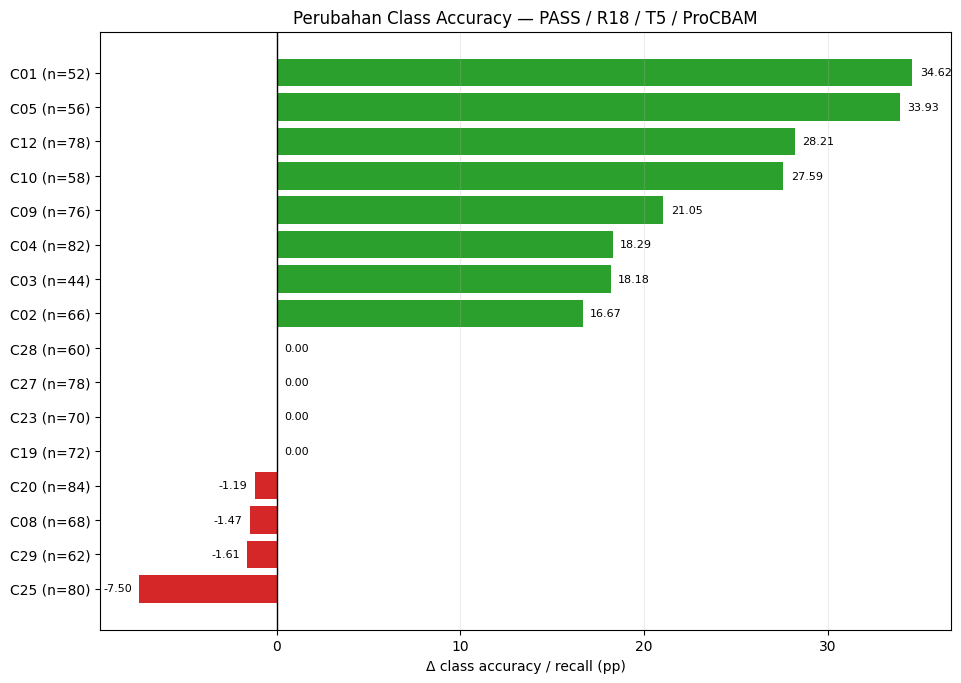

,class_id,class_name,recall_none_pct,recall_attention_pct,delta_recall_pp,support
0,25,C25,73.75,66.25,-7.50,80
1,29,C29,100.00,98.39,-1.61,62
2,8,C08,60.29,58.82,-1.47,68
3,20,C20,75.00,73.81,-1.19,84
4,19,C19,59.72,59.72,0.00,72
5,23,C23,87.14,87.14,0.00,70
6,27,C27,100.00,100.00,0.00,78
7,28,C28,98.33,98.33,0.00,60
15,2,C02,45.45,62.12,16.67,66
14,3,C03,40.91,59.09,18.18,44


In [18]:
TOP_N_CLASS_DELTA = 8


def class_delta_from_confusion(valid_runs, dataset, method, protocol, backbone, attention, class_labels=None):
    row_none, cm_none = fetch_cm(valid_runs, dataset, method, protocol, backbone, "none")
    row_attn, cm_attn = fetch_cm(valid_runs, dataset, method, protocol, backbone, attention)
    if cm_none is None or cm_attn is None:
        return pd.DataFrame()
    if cm_none.shape != cm_attn.shape:
        return pd.DataFrame()
    labels = [CLASS_LABELS.get(dataset, {}).get(i, f"C{i:02d}") for i in range(cm_none.shape[0])]
    norm_none, norm_attn = normalize_rows(cm_none), normalize_rows(cm_attn)
    tbl = pd.DataFrame({
        "class_id": range(cm_none.shape[0]),
        "class_name": labels,
        "recall_none_pct": np.diag(norm_none),
        "recall_attention_pct": np.diag(norm_attn),
        "delta_recall_pp": np.diag(norm_attn - norm_none),
        "support": cm_none.sum(axis=1).astype(int),
    })
    return tbl

class_delta_tbl = class_delta_from_confusion(valid, SELECT_DATASET, SELECT_METHOD, SELECT_PROTOCOL, SELECT_BACKBONE, COMPARE_ATTENTION)
if class_delta_tbl.empty:
    print("Class accuracy delta belum dapat dibuat untuk pasangan yang dipilih.")
else:
    pos = class_delta_tbl.nlargest(TOP_N_CLASS_DELTA, "delta_recall_pp")
    neg = class_delta_tbl.nsmallest(TOP_N_CLASS_DELTA, "delta_recall_pp")
    plot_tbl = pd.concat([neg, pos], ignore_index=True)
    plot_tbl = plot_tbl.sort_values("delta_recall_pp")
    y = np.arange(len(plot_tbl))
    colors = ["tab:red" if v < 0 else "tab:green" for v in plot_tbl["delta_recall_pp"]]
    fig, ax = plt.subplots(figsize=(9.5, max(5, 0.42*len(plot_tbl))), constrained_layout=True)
    ax.barh(y, plot_tbl["delta_recall_pp"], color=colors)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y, [f"{r.class_name} (n={int(r.support)})" for _, r in plot_tbl.iterrows()])
    ax.set_xlabel("Δ class accuracy / recall (pp)")
    ax.set_title(f"Perubahan Class Accuracy — {METHOD_LABELS.get(SELECT_METHOD, SELECT_METHOD)} / {SELECT_BACKBONE.upper()} / {SELECT_PROTOCOL} / {ATTN_LABELS.get(COMPARE_ATTENTION, COMPARE_ATTENTION)}")
    ax.grid(axis="x", alpha=.25)
    for yi, v in enumerate(plot_tbl["delta_recall_pp"]):
        ax.text(v + (0.4 if v >= 0 else -0.4), yi, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
    if GENERATE_FIGURES:
        fig.savefig(FIG_DIR / f"class_delta_diverging_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.png", dpi=180, bbox_inches="tight")
    plt.show()
    display(plot_tbl.round(2))
    exportable(class_delta_tbl).to_csv(TABLE_DIR / f"class_accuracy_delta_{SELECT_METHOD}_{SELECT_PROTOCOL}_{SELECT_BACKBONE}_{COMPARE_ATTENTION}.csv", index=False, encoding="utf-8-sig")


## 10F. *Confusion matrix* representatif

Sesuai arahan, confusion matrix **tidak** ditampilkan untuk semua model. Notebook ini otomatis memilih **2 kasus peningkatan paling besar** dan **1 kasus penurunan paling jelas** berdasarkan `ΔAIA`, lalu membuat heatmap:

- baseline `None`
- attention terpilih
- selisih `(attention − baseline)`

Anda tetap dapat mengganti daftar representatif secara manual bila ingin memilih kasus tertentu seperti **PASS + CBAM**.  

Setiap heatmap disimpan **terpisah** dalam PNG 300 dpi dan PDF, dengan skala warna yang sama untuk baseline dan attention.


In [ ]:
def representative_pairs_from_paired(pairs: pd.DataFrame, top_pos: int = 2, top_neg: int = 1):
    if pairs.empty:
        return pd.DataFrame()
    pairs = normalize_pair_schema(pairs)
    pos = pairs.nlargest(top_pos, "delta_aia_pp")
    neg = pairs.nsmallest(top_neg, "delta_aia_pp")
    out = pd.concat([pos, neg], ignore_index=True).drop_duplicates(subset=["method","protocol","backbone","attention"])
    return out

rep_pairs = representative_pairs_from_paired(paired, top_pos=2, top_neg=1)
if rep_pairs.empty:
    print("Belum ada pasangan representatif yang bisa diplot.")
else:
    display(rep_pairs[["method","protocol","backbone","attention","delta_aia_pp","delta_lta_pp"]].round(2))
    rep_rows = []
    for r in rep_pairs.itertuples(index=False):
        rn, cmn = fetch_cm(valid, r.dataset, r.method, r.protocol, r.backbone, "none")
        ra, cma = fetch_cm(valid, r.dataset, r.method, r.protocol, r.backbone, r.attention)
        if cmn is None or cma is None or cmn.shape != cma.shape:
            continue
        labels = [CLASS_LABELS.get(r.dataset, {}).get(i, f"C{i:02d}") for i in range(cmn.shape[0])]
        before, after = normalize_rows(cmn), normalize_rows(cma)
        diff = after - before
        vmax = max(1.0, float(np.abs(diff).max()))
        specs = [
            (before, "Blues", 0, 100, "Baseline (None)"),
            (after, "Blues", 0, 100, ATTN_LABELS.get(r.attention, r.attention)),
            (diff, "RdBu_r", -vmax, vmax, "Attention − None (pp)"),
        ]
        figure_files = {}
        for panel, (arr, cmap, vmin, vmax0, title) in zip(("none", r.attention, "delta"), specs):
            fig, ax = plt.subplots(figsize=(10, 10.5), constrained_layout=True)
            im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax0, interpolation="nearest")
            ax.set_title(f"{METHOD_LABELS.get(r.method, r.method)} / {r.backbone.upper()} / {r.protocol}\n{title}", fontsize=15)
            ax.set_xlabel("Predicted class", fontsize=14)
            ax.set_ylabel("True class", fontsize=14)
            if len(labels) <= 30:
                ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=12)
                ax.set_yticks(range(len(labels)), labels, fontsize=12)
            cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
            cbar.ax.tick_params(labelsize=12)
            filename = f"representative_confusion_{r.method}_{r.protocol}_{r.backbone}_{r.attention}_{panel}.png"
            if GENERATE_FIGURES:
                fig.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
                fig.savefig((FIG_DIR / filename).with_suffix(".pdf"), bbox_inches="tight")
            plt.show()
            figure_files[panel] = filename
        rep_rows.append({
            "method": r.method, "protocol": r.protocol, "backbone": r.backbone, "attention": r.attention,
            "delta_aia_pp": r.delta_aia_pp, "delta_lta_pp": r.delta_lta_pp,
            "baseline_figure_file": figure_files["none"],
            "attention_figure_file": figure_files[r.attention],
            "delta_figure_file": figure_files["delta"],
        })
    rep_df = pd.DataFrame(rep_rows)
    if not rep_df.empty:
        exportable(rep_df).to_csv(TABLE_DIR / "representative_confusion_cases.csv", index=False, encoding="utf-8-sig")


## 10G. Cross-check dengan seluruh tabel AI analysis

Bagian ini memuat **semua tabel hasil AI-ready analysis** agar dapat dibandingkan langsung dengan tabel utama Bab IV. Notebook mencoba membaca sumber data dari salah satu lokasi berikut:

1. folder `outputs/analysis_ai_ready/`
2. file ZIP `outputs/analysis_ai_ready/ai_ready_evaluation_bundle.zip`
3. file ZIP di lokasi yang Anda tentukan manual.

Jika tersedia, seluruh CSV akan disalin ke `outputs/analysis/ai_crosscheck/` dan juga dirangkum ke workbook Excel.  

In [20]:
AI_BUNDLE_OVERRIDE = None  # isi Path(...) bila zip berada di lokasi lain
AI_EXPECTED_FILES = [
    "valid_runs.csv", "paired_attention_effects.csv", "method_attention_gain.csv",
    "task_attention_delta.csv", "class_attention_delta.csv", "misclassification_delta.csv",
    "model_insights_all.csv", "bundle_insights_all.csv", "attention_insights_all.csv",
    "class_insights_final_all.csv", "AI_EVIDENCE_REPORT.md",
]


def load_ai_ready_tables(ai_dir: Path, ai_zip_override=None):
    loaded = {}
    missing = []
    source = None
    if ai_dir.is_dir() and any((ai_dir / name).exists() for name in AI_EXPECTED_FILES):
        source = "directory"
        for name in AI_EXPECTED_FILES:
            path = ai_dir / name
            if path.exists():
                if path.suffix.lower() == ".csv":
                    loaded[name] = pd.read_csv(path)
                else:
                    loaded[name] = path.read_text(encoding="utf-8")
            else:
                missing.append(name)
        return source, loaded, missing

    zip_path = None
    if ai_zip_override is not None:
        zip_path = Path(ai_zip_override)
    elif (ai_dir / "ai_ready_evaluation_bundle.zip").exists():
        zip_path = ai_dir / "ai_ready_evaluation_bundle.zip"
    if zip_path and zip_path.exists():
        source = f"zip:{zip_path}"
        with zipfile.ZipFile(zip_path) as zf:
            names = set(zf.namelist())
            for name in AI_EXPECTED_FILES:
                if name in names:
                    if name.endswith(".csv"):
                        with zf.open(name) as fh:
                            loaded[name] = pd.read_csv(fh)
                    else:
                        loaded[name] = zf.read(name).decode("utf-8")
                else:
                    missing.append(name)
        return source, loaded, missing

    return None, loaded, AI_EXPECTED_FILES.copy()

source, ai_loaded, ai_missing = load_ai_ready_tables(AI_READY_DIR, AI_BUNDLE_OVERRIDE)
if source is None:
    print("AI-ready outputs belum ditemukan. Bagian cross-check dilewati.")
else:
    print("Sumber AI-ready:", source)
    print("File ditemukan:", sorted(ai_loaded.keys()))
    if ai_missing:
        print("File belum tersedia:", ai_missing)
    manifest_rows = []
    for name, obj in ai_loaded.items():
        if isinstance(obj, pd.DataFrame):
            exportable(obj).to_csv(AI_CROSSCHECK_DIR / name, index=False, encoding="utf-8-sig")
            manifest_rows.append({"file": name, "rows": len(obj), "cols": len(obj.columns), "type": "csv"})
        else:
            (AI_CROSSCHECK_DIR / name).write_text(obj, encoding="utf-8")
            manifest_rows.append({"file": name, "rows": np.nan, "cols": np.nan, "type": "text"})
    manifest_df = pd.DataFrame(manifest_rows)
    display(manifest_df)
    exportable(manifest_df).to_csv(AI_CROSSCHECK_DIR / "ai_crosscheck_manifest.csv", index=False, encoding="utf-8-sig")

    # Workbook untuk cross-check seluruh tabel AI.
    try:
        with pd.ExcelWriter(AI_CROSSCHECK_DIR / "ai_crosscheck_tables.xlsx") as xw:
            for name, obj in ai_loaded.items():
                if isinstance(obj, pd.DataFrame):
                    sheet = name.replace(".csv", "")[:31]
                    obj.to_excel(xw, sheet_name=sheet, index=False)
        print("Workbook AI cross-check tersimpan:", AI_CROSSCHECK_DIR / "ai_crosscheck_tables.xlsx")
    except Exception as exc:
        print("Workbook AI cross-check tidak dibuat:", exc)

    # Tampilkan beberapa tabel kunci agar bisa langsung dicross-check di notebook.
    for key in ["model_insights_all.csv", "bundle_insights_all.csv", "attention_insights_all.csv", "class_insights_final_all.csv"]:
        if key in ai_loaded and isinstance(ai_loaded[key], pd.DataFrame):
            print(f"Preview: {key}")
            display(ai_loaded[key].head(10))


Sumber AI-ready: directory
File ditemukan: ['AI_EVIDENCE_REPORT.md', 'attention_insights_all.csv', 'bundle_insights_all.csv', 'class_attention_delta.csv', 'class_insights_final_all.csv', 'method_attention_gain.csv', 'misclassification_delta.csv', 'model_insights_all.csv', 'paired_attention_effects.csv', 'task_attention_delta.csv', 'valid_runs.csv']


,file,rows,cols,type
0,valid_runs.csv,80.0,23.0,csv
1,paired_attention_effects.csv,60.0,25.0,csv
2,method_attention_gain.csv,15.0,13.0,csv
3,task_attention_delta.csv,450.0,18.0,csv
4,class_attention_delta.csv,9600.0,23.0,csv
5,misclassification_delta.csv,15850.0,17.0,csv
6,model_insights_all.csv,80.0,17.0,csv
7,bundle_insights_all.csv,20.0,21.0,csv
8,attention_insights_all.csv,60.0,52.0,csv
9,class_insights_final_all.csv,1800.0,23.0,csv


Workbook AI cross-check tidak dibuat: No module named 'openpyxl'
Preview: model_insights_all.csv


,dataset,method,protocol,backbone,seed,attention,status,ready,run_id,source_machine,batch,aia_pct,lta_pct,macro_f1_pct,forgetting_rate_pct,bwt_pct,evidence_file
0,aid,fetril,T5,r18,1993,none,ready_snapshot,True,aid_fetril_t5_r18_none_seed1993,server,32,85.1122,77.80,77.7300,13.1517,-15.5726,valid_runs.csv
1,aid,fetril,T5,r18,1993,eca,ready_snapshot,True,aid_fetril_t5_r18_eca_seed1993,server,32,87.8103,81.45,81.3639,8.8373,-10.8198,valid_runs.csv
2,aid,fetril,T5,r18,1993,cbam,ready_snapshot,True,aid_fetril_t5_r18_cbam_seed1993,server,32,86.5015,78.75,78.7127,12.3445,-15.1245,valid_runs.csv
3,aid,fetril,T5,r18,1993,procbam,ready_snapshot,True,aid_fetril_t5_r18_procbam_seed1993,server,32,85.6727,77.50,77.2414,12.8480,-16.7437,valid_runs.csv
4,aid,fetril,T5,r34,1993,none,ready_snapshot,True,aid_fetril_t5_r34_none_seed1993,server,32,84.4092,76.05,75.9757,12.6314,-15.1310,valid_runs.csv
5,aid,fetril,T5,r34,1993,eca,ready_snapshot,True,aid_fetril_t5_r34_eca_seed1993,server,32,86.1343,78.30,78.4082,10.8804,-14.1790,valid_runs.csv
6,aid,fetril,T5,r34,1993,cbam,ready_snapshot,True,aid_fetril_t5_r34_cbam_seed1993,server,32,87.6291,80.70,80.4473,10.1425,-12.8891,valid_runs.csv
7,aid,fetril,T5,r34,1993,procbam,ready_snapshot,True,aid_fetril_t5_r34_procbam_seed1993,server,32,85.8807,78.50,78.3830,11.6585,-14.5061,valid_runs.csv
8,aid,fetril,T10,r18,1993,none,ready_snapshot,True,aid_fetril_t10_r18_none_seed1993,server,32,78.2576,67.25,67.8079,19.9223,-23.4547,valid_runs.csv
9,aid,fetril,T10,r18,1993,eca,ready_snapshot,True,aid_fetril_t10_r18_eca_seed1993,server,32,82.6092,74.40,74.1364,14.6153,-18.4200,valid_runs.csv


Preview: bundle_insights_all.csv


,dataset,method,protocol,backbone,seed,n_ready,n_expected,complete,n_fair_pairs,aia_none_pct,...,run_none_id,aia_eca_pct,lta_eca_pct,run_eca_id,aia_cbam_pct,lta_cbam_pct,run_cbam_id,aia_procbam_pct,lta_procbam_pct,run_procbam_id
0,aid,efc,T10,r18,1993,4,4,True,3,69.8563,...,aid_efc_t10_r18_none_seed1993,70.6400,65.90,aid_efc_t10_r18_eca_seed1993,76.6194,71.50,aid_efc_t10_r18_cbam_seed1993,76.0417,72.65,aid_efc_t10_r18_procbam_seed1993
1,aid,efc,T10,r34,1993,4,4,True,3,69.5760,...,aid_efc_t10_r34_none_seed1993,70.2131,65.95,aid_efc_t10_r34_eca_seed1993,74.0022,69.70,aid_efc_t10_r34_cbam_seed1993,75.5213,70.85,aid_efc_t10_r34_procbam_seed1993
2,aid,efc,T5,r18,1993,4,4,True,3,76.8779,...,aid_efc_t5_r18_none_seed1993,78.3558,73.75,aid_efc_t5_r18_eca_seed1993,81.4493,76.90,aid_efc_t5_r18_cbam_seed1993,82.3931,78.50,aid_efc_t5_r18_procbam_seed1993
3,aid,efc,T5,r34,1993,4,4,True,3,76.0129,...,aid_efc_t5_r34_none_seed1993,77.3818,72.90,aid_efc_t5_r34_eca_seed1993,79.7091,75.00,aid_efc_t5_r34_cbam_seed1993,80.0833,75.45,aid_efc_t5_r34_procbam_seed1993
4,aid,fecam,T10,r18,1993,4,4,True,3,83.1618,...,aid_fecam_t10_r18_none_seed1993,83.4116,76.10,aid_fecam_t10_r18_eca_seed1993,85.3862,79.25,aid_fecam_t10_r18_cbam_seed1993,85.8252,79.90,aid_fecam_t10_r18_procbam_seed1993
5,aid,fecam,T10,r34,1993,4,4,True,3,77.5917,...,aid_fecam_t10_r34_none_seed1993,79.3417,70.80,aid_fecam_t10_r34_eca_seed1993,78.9518,70.40,aid_fecam_t10_r34_cbam_seed1993,78.4803,70.95,aid_fecam_t10_r34_procbam_seed1993
6,aid,fecam,T5,r18,1993,4,4,True,3,87.6584,...,aid_fecam_t5_r18_none_seed1993,86.9438,80.80,aid_fecam_t5_r18_eca_seed1993,88.3665,83.10,aid_fecam_t5_r18_cbam_seed1993,88.3234,82.45,aid_fecam_t5_r18_procbam_seed1993
7,aid,fecam,T5,r34,1993,4,4,True,3,83.0136,...,aid_fecam_t5_r34_none_seed1993,84.9720,78.40,aid_fecam_t5_r34_eca_seed1993,84.9550,77.90,aid_fecam_t5_r34_cbam_seed1993,84.1502,77.20,aid_fecam_t5_r34_procbam_seed1993
8,aid,fetril,T10,r18,1993,4,4,True,3,78.2576,...,aid_fetril_t10_r18_none_seed1993,82.6092,74.40,aid_fetril_t10_r18_eca_seed1993,81.3225,72.70,aid_fetril_t10_r18_cbam_seed1993,81.4903,71.85,aid_fetril_t10_r18_procbam_seed1993
9,aid,fetril,T10,r34,1993,4,4,True,3,78.7978,...,aid_fetril_t10_r34_none_seed1993,84.1037,77.00,aid_fetril_t10_r34_eca_seed1993,80.1633,70.85,aid_fetril_t10_r34_cbam_seed1993,80.8023,71.75,aid_fetril_t10_r34_procbam_seed1993


Preview: attention_insights_all.csv


,dataset,method,protocol,backbone,seed,attention,status,baseline_status,attention_status,baseline_run_id,...,classes_more_forgetting,classes_same_forgetting,mean_delta_class_forgetting_pp,confusion_directions_changed,directions_errors_reduced,directions_errors_increased,max_reduced_confusion,max_reduced_errors,max_increased_confusion,max_increased_errors
0,aid,efc,T10,r18,1993,cbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r18_none_seed1993,...,7,5,-6.3927,176,102,74,Port -> Parking,24,Port -> Bridge,12
1,aid,efc,T10,r18,1993,eca,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r18_none_seed1993,...,10,5,-1.2899,183,98,85,Meadow -> Beach,17,Meadow -> Desert,18
2,aid,efc,T10,r18,1993,procbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r18_none_seed1993,...,7,5,-7.7341,176,106,70,Port -> Parking,24,Meadow -> BareLand,10
3,aid,efc,T10,r34,1993,cbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r34_none_seed1993,...,10,3,-3.8468,200,106,94,Port -> Parking,25,Meadow -> BareLand,21
4,aid,efc,T10,r34,1993,eca,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r34_none_seed1993,...,10,4,-0.4881,200,108,92,Meadow -> Beach,22,Meadow -> Desert,34
5,aid,efc,T10,r34,1993,procbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t10_r34_none_seed1993,...,6,8,-6.2614,200,106,94,Meadow -> Beach,20,DenseResidential -> Commercial,13
6,aid,efc,T5,r18,1993,cbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t5_r18_none_seed1993,...,4,8,-3.5021,160,100,60,Meadow -> Beach,18,Desert -> BareLand,13
7,aid,efc,T5,r18,1993,eca,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t5_r18_none_seed1993,...,9,7,-1.0390,163,94,69,Meadow -> Beach,20,Meadow -> BareLand,26
8,aid,efc,T5,r18,1993,procbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t5_r18_none_seed1993,...,3,5,-6.4144,161,96,65,Stadium -> Center,18,Meadow -> BareLand,12
9,aid,efc,T5,r34,1993,cbam,paired_valid,ready_snapshot,ready_snapshot,aid_efc_t5_r34_none_seed1993,...,6,5,-2.5192,147,93,54,Meadow -> Forest,15,Meadow -> BareLand,22


Preview: class_insights_final_all.csv


,dataset,method,protocol,backbone,attention,seed,batch,source_machine,attention_run_id,task_id,...,introduced_task,is_new_class,attention_support,correct_attention,attention_class_accuracy_pct,baseline_class_accuracy_pct,baseline_support,correct_none,baseline_run_id,delta_class_accuracy_pp
0,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,58,25,43.103448,34.482759,58,20,aid_efc_t10_r18_none_seed1993,8.620690
1,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,52,16,30.769231,19.230769,52,10,aid_efc_t10_r18_none_seed1993,11.538462
2,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,66,24,36.363636,12.121212,66,8,aid_efc_t10_r18_none_seed1993,24.242424
3,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,44,36,81.818182,40.909091,44,18,aid_efc_t10_r18_none_seed1993,40.909091
4,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,82,47,57.317073,50.000000,82,41,aid_efc_t10_r18_none_seed1993,7.317073
5,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,56,28,50.000000,39.285714,56,22,aid_efc_t10_r18_none_seed1993,10.714286
6,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,74,61,82.432432,72.972973,74,54,aid_efc_t10_r18_none_seed1993,9.459459
7,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,48,33,68.750000,54.166667,48,26,aid_efc_t10_r18_none_seed1993,14.583333
8,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,68,50,73.529412,73.529412,68,50,aid_efc_t10_r18_none_seed1993,0.000000
9,aid,efc,T10,r18,cbam,1993,12,server,aid_efc_t10_r18_cbam_seed1993,9,...,0,False,76,26,34.210526,19.736842,76,15,aid_efc_t10_r18_none_seed1993,14.473684


## 10H. Ringkasan file output untuk Bab IV

Setelah seluruh sel di atas dijalankan, file penting untuk penulisan Bab IV akan berada di dua folder berikut:

- `outputs/analysis/tables_bab4/`
- `outputs/analysis/figures/`

Sedangkan seluruh tabel hasil AI untuk keperluan *cross-check* akan berada di:

- `outputs/analysis/ai_crosscheck/`

Dengan struktur ini, Anda dapat memisahkan **tabel/grafik yang masuk naskah** dari **tabel audit/internal** yang hanya dipakai untuk verifikasi.  

In [21]:
summary_rows = []
for folder in [TABLE_DIR, FIG_DIR, AI_CROSSCHECK_DIR]:
    if folder.exists():
        for p in sorted(folder.iterdir()):
            if p.is_file():
                summary_rows.append({
                    "folder": str(folder.relative_to(PROJECT_ROOT)),
                    "file": p.name,
                    "size_kb": round(p.stat().st_size / 1024, 2),
                })
summary_df = pd.DataFrame(summary_rows)
if summary_df.empty:
    print("Belum ada file output tambahan yang dibuat.")
else:
    display(summary_df)
    exportable(summary_df).to_csv(OUTPUT_DIR / "bab4_output_inventory.csv", index=False, encoding="utf-8-sig")


,folder,file,size_kb
0,outputs\analysis\tables_bab4,class_accuracy_delta_pass_T5_r18_procbam.csv,1.74
1,outputs\analysis\tables_bab4,heatmap_delta_aia_source.csv,1.46
2,outputs\analysis\tables_bab4,heatmap_delta_bwt_source.csv,1.47
3,outputs\analysis\tables_bab4,heatmap_delta_fr_source.csv,1.51
4,outputs\analysis\tables_bab4,heatmap_delta_lta_source.csv,1.36
5,outputs\analysis\tables_bab4,old_new_summary_pass_T5_r18.csv,0.53
6,outputs\analysis\tables_bab4,old_new_taskwise_pass_T5_r18.csv,2.18
7,outputs\analysis\tables_bab4,paired_attention_full_details_all.csv,62.18
8,outputs\analysis\tables_bab4,representative_confusion_cases.csv,0.37
9,outputs\analysis\tables_bab4,table_4_1_aia_t5.csv,0.94


## 12. Bab IV — paket publikasi final (16 tabel + 17 gambar)

Bagian ini **ditambahkan tanpa mengubah cell audit / evaluasi lama**. Sumbernya `ai_ready_evaluation_with_feature_space.zip`, yang memuat **80 model**, **60 fair pairs**, serta feature-space analysis. Tidak perlu checkpoint, training, atau inference ulang.

**Ruang lingkup:** AID, seed 1993. Tabel 4.1–4.4 mengambil nilai canonical AIA/LTA; Tabel 4.5–4.6 memakai delta yang sudah diaudit. Korelasi/similarity digunakan sebagai observasi deskriptif, bukan bukti hubungan kausal.

**Catatan penting:** Gambar 4.11 dan 4.12 harus menggunakan **citra AID asli**. Jika belum ada PNG sebelumnya dan root dataset AID tidak ditemukan, status gambar akan menjadi `missing_source`, sementara tabel/gambar lain tetap dihasilkan. Tidak membuat placeholder sintetis.

### 12.1 Pustaka, konstanta, audit ZIP

In [22]:
"""Publication-ready Bab IV (AID), powered by audited AI-ready feature-space ZIP.

Self-contained, offline. No training, checkpoint loading, or recalculation of
canonical AIA/LTA/FR/BWT. The original notebook can also embed this source.
"""
from __future__ import annotations

import io
import json
import shutil
import zipfile
from datetime import datetime, timezone
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

METHODS_PUB = ('fetril', 'fecam', 'ssre', 'pass', 'efc')
BACKBONES_PUB = ('r18', 'r34')
PROTOCOLS_PUB = ('T5', 'T10')
ATTNS_PUB = ('eca', 'cbam', 'procbam')
METHOD_NAMES_PUB = {'fetril': 'FeTrIL', 'fecam': 'FeCAM', 'ssre': 'SSRE', 'pass': 'PASS', 'efc': 'EFC'}
LITERATURE_PAIRS_PUB = (
    ('Stadium', 'Playground'), ('BareLand', 'Desert'), ('Resort', 'Park'),
    ('Church', 'Commercial'), ('Beach', 'Port'), ('Square', 'Center'),
    ('MediumResidential', 'DenseResidential'),
)
BUNDLE_REQUIRED_PUB = {
    'model_insights_all.csv', 'paired_attention_effects.csv', 'attention_insights_all.csv',
    'class_insights_final_all.csv', 'class_accuracy_long.csv', 'misclassification_long.csv',
    'class_label_map.csv', 'task_attention_delta.csv', 'class_forgetting_attention_delta.csv',
    'misclassification_delta.csv',
    'feature_space/feature_analysis_manifest.json',
    'feature_space/inter_class_similarity.csv', 'feature_space/feature_confusion_join.csv',
    'feature_space/intra_class_dispersion.csv', 'feature_space/attention_feature_summary.csv',
    'feature_space/feature_contact_sheet_selection.csv',
}


def _assert_columns(df, name, columns):
    absent = set(columns) - set(df.columns)
    if absent:
        raise ValueError(f'{name} tidak memiliki kolom wajib: {sorted(absent)}')


def _write_table(df, target, caption):
    df.to_csv(target, index=False, encoding='utf-8-sig', float_format='%.7f')
    return {'name': target.name, 'caption': caption, 'rows': len(df), 'columns': len(df.columns), 'status': 'generated'}


def _pair_sort(df):
    d = df.copy()
    d['_method_order'] = pd.Categorical(d['method'], categories=METHODS_PUB, ordered=True)
    d['_backbone_order'] = pd.Categorical(d['backbone'], categories=BACKBONES_PUB, ordered=True)
    d['_protocol_order'] = pd.Categorical(d['protocol'], categories=PROTOCOLS_PUB, ordered=True)
    d['_attention_order'] = pd.Categorical(d['attention'], categories=ATTNS_PUB, ordered=True)
    return d.sort_values(['_method_order', '_backbone_order', '_protocol_order', '_attention_order']).drop(columns=['_method_order','_backbone_order','_protocol_order','_attention_order'])


def load_bab4_evidence(bundle_path):
    bundle_path = Path(bundle_path)
    if not bundle_path.is_file():
        raise FileNotFoundError(f'ZIP gabungan evaluasi tidak ditemukan: {bundle_path}')
    result = {}
    with zipfile.ZipFile(bundle_path) as zin:
        if zin.testzip() is not None:
            raise ValueError('File ZIP gagal pemeriksaan CRC.')
        missing = BUNDLE_REQUIRED_PUB - set(zin.namelist())
        if missing:
            raise FileNotFoundError(f'File evidence wajib hilang dari ZIP: {sorted(missing)}')
        for name in zin.namelist():
            if name.endswith('.csv'):
                if name.endswith('feature_analysis_errors.csv') and zin.getinfo(name).file_size <= 5:
                    continue
                try:
                    result[name] = pd.read_csv(io.BytesIO(zin.read(name)))
                except pd.errors.EmptyDataError:
                    result[name] = pd.DataFrame()
            elif name.endswith('.json'):
                result[name] = json.loads(zin.read(name).decode('utf-8-sig'))
    runs = result['model_insights_all.csv']
    pairs = result['paired_attention_effects.csv']
    fs = result['feature_space/attention_feature_summary.csv']
    _assert_columns(runs, 'model_insights_all.csv', ['dataset','method','protocol','backbone','attention','seed','aia_pct','lta_pct','run_id'])
    _assert_columns(pairs, 'paired_attention_effects.csv', ['method','protocol','backbone','attention','delta_aia_pp','delta_lta_pp','delta_fr_pp','delta_bwt_pp','baseline_run_id','attention_run_id'])
    _assert_columns(fs, 'attention_feature_summary.csv', ['baseline_run_id','attention_run_id','mean_delta_inter_class_similarity','mean_delta_intra_dispersion','mean_delta_mutual_confusion_pp','delta_aia_pp','delta_lta_pp'])
    if len(runs) != 80 or len(pairs) != 60 or len(fs) != 60:
        raise ValueError(f'Coverage tidak lengkap: model={len(runs)}/80, pairs={len(pairs)}/60, feature summary={len(fs)}/60. Tidak membuat tabel final dari data parsial.')
    expected_keys = set(product(METHODS_PUB, PROTOCOLS_PUB, BACKBONES_PUB, ('none',) + ATTNS_PUB))
    actual_keys = set(map(tuple, runs[['method','protocol','backbone','attention']].itertuples(index=False, name=None)))
    if expected_keys != actual_keys:
        raise ValueError(f'Grid model tidak tepat: missing={len(expected_keys-actual_keys)}, extra={len(actual_keys-expected_keys)}')
    if not runs['ready'].fillna(False).all():
        raise ValueError('Tidak semua 80 model berstatus ready.')
    if runs['run_id'].duplicated().any() or pairs.duplicated(['method','protocol','backbone','attention']).any():
        raise ValueError('Ditemukan duplikat konfigurasi/run_id pada ZIP.')
    assert len(result['feature_space/inter_class_similarity.csv']) == 80 * 435
    assert len(result['feature_space/intra_class_dispersion.csv']) == 80 * 30
    assert len(result['feature_space/feature_confusion_join.csv']) == 80 * 435
    assert len(result['class_insights_final_all.csv']) == 60 * 30
    fv = result['feature_space/feature_analysis_validated_runs.csv']
    _assert_columns(fv, 'feature_analysis_validated_runs.csv', ['run_id','feature_dim','n_samples','status'])
    if (len(fv)!=80 or fv.run_id.duplicated().any() or set(fv.run_id)!=set(runs.run_id)
        or not (fv.feature_dim==512).all() or not (fv.n_samples==2000).all()
        or not (fv.status=='validated').all()):
        raise ValueError('Audit feature-space 80 run tidak cocok dengan model utama.')
    # Verify exact joins, and that delta AIA/LTA in feature summaries are the canonical deltas.
    merged=fs.merge(pairs[['attention_run_id','baseline_run_id','delta_aia_pp','delta_lta_pp','source_machine','batch']],
                    on=['attention_run_id','baseline_run_id'],how='outer',validate='one_to_one',suffixes=('_feature','_canonical'),indicator=True)
    if len(merged)!=60 or not (merged['_merge']=='both').all():
        raise ValueError('Ada pasangan feature-space yang tidak ada pada paired_attention_effects.csv.')
    for m in ('delta_aia_pp','delta_lta_pp'):
        if not np.allclose(merged[m+'_feature'],merged[m+'_canonical'],atol=1e-7,rtol=0):
            raise ValueError(f'Metrik canonical {m} tidak cocok dengan feature summary.')
    if not (merged.batch_feature==merged.batch_canonical).all() or not (merged.source_machine_feature==merged.source_machine_canonical).all():
        raise ValueError('Fairness batch/machine pada pasangan feature tidak cocok dengan canonical pairs.')
    manifest=result['feature_space/feature_analysis_manifest.json']
    if int(manifest.get('validated_embedded_runs', 80))!=80 or int(manifest.get('n_fair_feature_attention_pairs',60))!=60:
        raise ValueError('Manifest feature-space menyatakan coverage berbeda dari 80 model / 60 pairs.')
    return result



### 12.2 Tabel 4.1–4.16

In [23]:

def build_tables_bab4(e, table_dir):
    table_dir = Path(table_dir); table_dir.mkdir(parents=True, exist_ok=True)
    recs = []
    runs = e['model_insights_all.csv'].copy()
    pairs = e['paired_attention_effects.csv'].copy()
    feature = e['feature_space/attention_feature_summary.csv'].copy()
    class_final = e['class_insights_final_all.csv'].copy()
    keyidx = {tuple(r[k] for k in ['method','backbone','protocol','attention']): r for _,r in runs.iterrows()}
    pidx = {tuple(r[k] for k in ['method','backbone','protocol','attention']): r for _,r in pairs.iterrows()}

    # 4.1-4.4: Canonical run metrics, no recomputation.
    for no,protocol,metric,caption in [
        (1,'T5','aia_pct','AIA T=5 (%)'), (2,'T5','lta_pct','LTA T=5 (%)'),
        (3,'T10','aia_pct','AIA T=10 (%)'), (4,'T10','lta_pct','LTA T=10 (%)'),
    ]:
        rows = []
        for method,backbone in product(METHODS_PUB,BACKBONES_PUB):
            r={'Method':METHOD_NAMES_PUB[method], 'Backbone':f'ResNet-{backbone[1:]}'}
            for att in ('none',)+ATTNS_PUB:
                r[{'none':'None','eca':'ECA','cbam':'CBAM','procbam':'ProCBAM'}[att]] = float(keyidx[method,backbone,protocol,att][metric])
            rows.append(r)
        recs.append(_write_table(pd.DataFrame(rows),table_dir/f'Tabel_4_{no:02d}.csv',caption))

    # 4.5-4.6: Six paired deltas / method-backbone row.
    for no,protocol in [(5,'T5'),(6,'T10')]:
        rows=[]
        for method,backbone in product(METHODS_PUB,BACKBONES_PUB):
            r={'Method':METHOD_NAMES_PUB[method], 'Backbone':f'ResNet-{backbone[1:]}'}
            for att in ATTNS_PUB:
                x=pidx[method,backbone,protocol,att]
                r[f'ΔAIA {att.upper()} (pp)']=float(x.delta_aia_pp)
                r[f'ΔLTA {att.upper()} (pp)']=float(x.delta_lta_pp)
            rows.append(r)
        recs.append(_write_table(pd.DataFrame(rows),table_dir/f'Tabel_4_{no:02d}.csv',f'Delta AIA/LTA T={protocol[1:]} (pp)'))

    # 4.7 FR/BWT: lower FR is better, higher BWT is better.
    rows=[]
    for a in ATTNS_PUB:
        g=pairs[pairs.attention==a]
        rows.append({'Attention':a.upper(),'N pairs':len(g),'FR membaik (ΔFR<0)':int((g.delta_fr_pp<0).sum()),
                     'Mean ΔFR (pp)':g.delta_fr_pp.mean(), 'BWT membaik (ΔBWT>0)':int((g.delta_bwt_pp>0).sum()),
                     'Mean ΔBWT (pp)':g.delta_bwt_pp.mean()})
    recs.append(_write_table(pd.DataFrame(rows),table_dir/'Tabel_4_07.csv','Ringkasan FR dan BWT'))

    # 4.8 balanced extremes per-class forgetting; negative delta means improvement.
    forg = e['class_forgetting_attention_delta.csv'].copy()
    forg = forg[forg.support>=10].copy()
    fsort = ['delta_forgetting_pp','method','protocol','backbone','attention','class_id']
    fg = forg[forg.delta_forgetting_pp < 0].sort_values(fsort).head(4).copy()
    fb = forg[forg.delta_forgetting_pp > 0].sort_values(fsort, ascending=[False,True,True,True,True,True]).head(4).copy()
    f8=pd.concat([fg,fb],ignore_index=True)
    f8.insert(0,'Outcome', ['Forgetting berkurang']*len(fg)+['Forgetting meningkat']*len(fb))
    f8=f8.rename(columns={'class_name':'Class','baseline_forgetting_pp':'FR None (pp)',
                          'attention_forgetting_pp':'FR Attention (pp)','delta_forgetting_pp':'ΔForgetting (pp)'})
    recs.append(_write_table(f8[['Outcome','method','protocol','backbone','attention','Class','FR None (pp)','FR Attention (pp)','ΔForgetting (pp)','support','baseline_run_id','attention_run_id']],table_dir/'Tabel_4_08.csv','Contoh per-class forgetting terbesar (4 membaik, 4 memburuk)'))

    # 4.9: macro-average over conditions, not raw task-weighted mean; exclude task0.
    td = e['task_attention_delta.csv'].copy(); td=td[td.task_id>0].copy()
    condition_cols=['dataset','method','protocol','backbone','seed','attention']
    cond=(td.groupby(condition_cols,as_index=False)
          .agg(mean_delta_old_pp=('delta_old_pp','mean'),mean_delta_new_pp=('delta_new_pp','mean')))
    rows=[]
    for att in ATTNS_PUB:
        g=cond[cond.attention==att]; task=td[td.attention==att]
        rows.append({'Attention':att.upper(),'N paired conditions':len(g),
                     'Mean ΔOld Accuracy (pp)':g.mean_delta_old_pp.mean(),
                     'Mean ΔNew Accuracy (pp)':g.mean_delta_new_pp.mean(),
                     'Old tasks meningkat':int((task.delta_old_pp>0).sum()),
                     'New tasks meningkat':int((task.delta_new_pp>0).sum()),
                     'N incremental tasks evaluated':len(task)})
    t9=pd.DataFrame(rows)
    recs.append(_write_table(t9,table_dir/'Tabel_4_09.csv','Ringkasan old/new accuracy, macro mean per 20 pasangan'))

    # 4.10 Macro-F1 and class changes on final task (60×30 class rows).
    t10=[]
    for att in ATTNS_PUB:
        g=pairs[pairs.attention==att]
        c=class_final[class_final.attention==att]
        t10.append({'Attention':att.upper(),'Macro-F1 naik (pairs)':int((g.delta_macro_f1_pp>0).sum()),
                    'N pairs':len(g),'Mean ΔMacro-F1 (pp)':g.delta_macro_f1_pp.mean(),
                    'Class accuracy naik':int((c.delta_class_accuracy_pp>1e-9).sum()),
                    'Class accuracy turun':int((c.delta_class_accuracy_pp< -1e-9).sum()),
                    'Class accuracy tetap':int((c.delta_class_accuracy_pp.abs()<=1e-9).sum()),
                    'N class observations':len(c),'Mean ΔClass Accuracy (pp)':c.delta_class_accuracy_pp.mean()})
    recs.append(_write_table(pd.DataFrame(t10),table_dir/'Tabel_4_10.csv','Macro-F1 dan class accuracy final'))

    # 4.11 extremes with deterministic tie-break and preserved source run ids.
    base_keys=['delta_class_accuracy_pp','method','protocol','backbone','attention','class_id']
    cp=class_final[class_final.delta_class_accuracy_pp>0].sort_values(base_keys,ascending=[False,True,True,True,True,True]).head(4)
    cn=class_final[class_final.delta_class_accuracy_pp<0].sort_values(base_keys).head(4)
    ex=pd.concat([cp,cn],ignore_index=True)
    ex.insert(0,'Outcome',['Kenaikan']*len(cp)+['Penurunan']*len(cn))
    ex=ex.rename(columns={'class_name':'Class','baseline_class_accuracy_pct':'Baseline accuracy (%)',
                          'attention_class_accuracy_pct':'Attention accuracy (%)',
                          'delta_class_accuracy_pp':'ΔAccuracy (pp)','attention_support':'Support'})
    ex_cols=['Outcome','method','protocol','backbone','attention','Class','Support','Baseline accuracy (%)','Attention accuracy (%)','ΔAccuracy (pp)','baseline_run_id','attention_run_id']
    recs.append(_write_table(ex[ex_cols],table_dir/'Tabel_4_11.csv','Extreme final class accuracy: empat naik, empat turun'))

    # 4.12 same unordered literature pairs, aggregate across 20 baseline representations.
    lc=e['feature_space/feature_confusion_join.csv']
    lc=lc[lc.attention=='none'].copy()
    lc['pair_key']=lc.apply(lambda r:frozenset((str(r.class_i_name).casefold(),str(r.class_j_name).casefold())),axis=1)
    t12=[]
    for first,second in LITERATURE_PAIRS_PUB:
        g=lc[lc.pair_key==frozenset((first.casefold(),second.casefold()))]
        if len(g)!=20:
            raise ValueError(f'Pasangan literatur {first}↔{second} memiliki {len(g)} baseline, diharapkan 20')
        t12.append({'Pair':f'{first} ↔ {second}', 'N baseline models':len(g),
                    'Mean centroid cosine similarity':g.centroid_cosine_similarity.mean(),
                    'Mean symmetric confusion (%)':g.symmetric_confusion_rate_pct.mean(),
                    'Min similarity':g.centroid_cosine_similarity.min(),
                    'Max similarity':g.centroid_cosine_similarity.max()})
    recs.append(_write_table(pd.DataFrame(t12),table_dir/'Tabel_4_12.csv','Pasangan kelas literatur: mean over 20 baseline models'))

    # 4.13 baseline-only aggregation avoids mixing attention with baseline.
    intra=e['feature_space/intra_class_dispersion.csv']
    intra=intra[intra.attention=='none'].copy()
    t13=(intra.groupby(['class_id','class_name'],as_index=False)
         .agg(n_baseline_models=('run_id','nunique'),
              mean_dispersion=('mean_cosine_distance_to_centroid','mean'),
              mean_final_error_pct=('final_class_error_rate_pct','mean'),
              mean_forgetting_pp=('class_forgetting_pp','mean'),
              mean_support=('support','mean')))
    if len(t13)!=30 or (t13.n_baseline_models!=20).any():
        raise ValueError('Tabel 4.13 memerlukan 30 kelas × 20 model baseline lengkap')
    t13=t13.sort_values(['mean_dispersion','class_id'],ascending=[False,True]).reset_index(drop=True)
    t13.insert(0,'Rank',np.arange(1,len(t13)+1))
    recs.append(_write_table(t13.head(10),table_dir/'Tabel_4_13.csv','Sepuluh kelas baseline dengan mean feature dispersion tertinggi'))
    _write_table(t13,table_dir/'Lampiran_dispersion_30_kelas.csv','Ranking 30 kelas baseline')

    # 4.14 summary across 20 valid conditions for each attention.
    fs_rows=[]
    for att in ATTNS_PUB:
        g=feature[feature.attention==att]
        if len(g)!=20:
            raise ValueError('Tabel 4.14 membutuhkan 20 pasangan / attention')
        fs_rows.append({'Attention':att.upper(),'N fair pairs':len(g),
                        'Mean ΔAIA (pp)':g.delta_aia_pp.mean(),'Mean ΔLTA (pp)':g.delta_lta_pp.mean(),
                        'Mean ΔCentroid Similarity':g.mean_delta_inter_class_similarity.mean(),
                        'Similarity turun (pairs)':int((g.mean_delta_inter_class_similarity<0).sum()),
                        'Mean ΔIntra Dispersion':g.mean_delta_intra_dispersion.mean(),
                        'Dispersion turun (pairs)':int((g.mean_delta_intra_dispersion<0).sum()),
                        'Mean ΔMutual Confusion (pp)':g.mean_delta_mutual_confusion_pp.mean(),
                        'Confusion turun (pairs)':int((g.mean_delta_mutual_confusion_pp<0).sum())})
    t14=pd.DataFrame(fs_rows)
    recs.append(_write_table(t14,table_dir/'Tabel_4_14.csv','Ringkasan efek attention dalam feature-space'))

    # 4.15 derive representative cases if feature_representative_cases.csv was NOT bundled.
    selectors=[
        ('Largest mean confusion reduction','mean_delta_mutual_confusion_pp','min'),
        ('Largest mean centroid similarity reduction','mean_delta_inter_class_similarity','min'),
        ('Largest mean compactness improvement','mean_delta_intra_dispersion','min'),
        ('Largest AIA degradation','delta_aia_pp','min'),
    ]
    cases=[]
    for label,col,direction in selectors:
        g=feature.sort_values([col,'method','protocol','backbone','attention'],ascending=[direction!='max',True,True,True,True])
        # Only mark degradation if actual AIA is negative.
        if label.endswith('degradation'):
            g=g[g.delta_aia_pp<0]
        if g.empty:continue
        x=g.iloc[0]
        cases.append({'Criterion':label,'Selected metric':col,'Metric value':float(x[col]),
                      'Method':METHOD_NAMES_PUB[x.method],'Protocol':x.protocol,
                      'Backbone':x.backbone.upper(),'Attention':x.attention.upper(),
                      'ΔAIA (pp)':float(x.delta_aia_pp), 'ΔLTA (pp)':float(x.delta_lta_pp),
                      'Mean ΔSimilarity':float(x.mean_delta_inter_class_similarity),
                      'Mean ΔDispersion':float(x.mean_delta_intra_dispersion),
                      'Mean ΔMutual Confusion (pp)':float(x.mean_delta_mutual_confusion_pp),
                      'Baseline Run ID':x.baseline_run_id,'Attention Run ID':x.attention_run_id})
    recs.append(_write_table(pd.DataFrame(cases),table_dir/'Tabel_4_15.csv','Kasus representatif berdasarkan kriteria objektif'))

    # 4.16 off-diagonal errors, balanced across improvements and degradations, with predefined cases.
    md=e['misclassification_delta.csv']
    positives=md[md.errors_reduced>0].sort_values(['errors_reduced','method','protocol','backbone','attention','true_class_id','predicted_class_id'],ascending=[False,True,True,True,True,True,True]).head(5)
    negatives=md[md.errors_reduced<0].sort_values(['errors_reduced','method','protocol','backbone','attention','true_class_id','predicted_class_id']).head(5)
    curated=md[((md.method=='fecam')&(md.protocol=='T10')&(md.backbone=='r18')&(md.attention=='cbam')&
                (md.true_class=='Desert')&(md.predicted_class=='BareLand')) |
               ((md.method=='pass')&(md.protocol=='T10')&(md.backbone=='r18')&(md.attention=='cbam')&
                (md.true_class=='Pond')&(md.predicted_class=='Park'))]
    t16=pd.concat([curated,positives,negatives],ignore_index=True).drop_duplicates(subset=['baseline_run_id','attention_run_id','true_class_id','predicted_class_id'])
    t16=t16.copy();t16.insert(0,'Interpretation',np.where(t16.errors_reduced>0,'Errors berkurang',np.where(t16.errors_reduced<0,'Errors meningkat','Tidak berubah')))
    t16=t16.rename(columns={'true_class':'True class','predicted_class':'Predicted class','errors_none':'Errors None',
                             'errors_attention':'Errors Attention','errors_reduced':'Errors reduced (count)','delta_error_rate_pp':'ΔError Rate (pp)'})
    recs.append(_write_table(t16[['Interpretation','method','protocol','backbone','attention','True class','Predicted class',
                                  'support','Errors None','Errors Attention','Errors reduced (count)','ΔError Rate (pp)','baseline_run_id','attention_run_id']],
                            table_dir/'Tabel_4_16.csv','Misclassification changes: peningkatan dan degradasi'))
    return recs, {'table_4_9':t9, 'table_4_11':ex,'table_4_14':t14,'table_4_15':pd.DataFrame(cases)}



### 12.3 Utilitas heatmap dan rekonstruksi confusion matrix

In [ ]:

def _plot_heatmap(values, row_labels, col_labels, title, dest, reverse=False, value_format='{:+.2f}', x_label='Attention mechanism', y_label='Method / Backbone / Protocol', font_scale=1.0):
    a=np.asarray(values,dtype=float)
    max_abs=max(0.1,np.nanmax(np.abs(a)))
    fig,ax=plt.subplots(figsize=(10.5,max(10,0.5*len(row_labels))),constrained_layout=True)
    im=ax.imshow(a,cmap='RdYlGn_r' if reverse else 'RdYlGn',norm=TwoSlopeNorm(vmin=-max_abs,vcenter=0,vmax=max_abs),aspect='auto')
    ax.set_xticks(range(len(col_labels)),col_labels,fontsize=13*font_scale)
    ax.set_yticks(range(len(row_labels)),row_labels,fontsize=12*font_scale)
    ax.set_title(title,fontsize=15*font_scale,pad=14)
    ax.set_xlabel(x_label,fontsize=14*font_scale); ax.set_ylabel(y_label,fontsize=14*font_scale)
    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            if np.isfinite(a[i,j]):
                ax.text(j,i,value_format.format(a[i,j]),ha='center',va='center',fontsize=12*font_scale,color='black')
    colorbar=fig.colorbar(im,ax=ax,label='Δ metric (percentage points)',fraction=0.044,pad=0.03)
    colorbar.ax.yaxis.label.set_size(13*font_scale)
    colorbar.ax.tick_params(labelsize=12*font_scale)
    fig.savefig(dest,dpi=300,bbox_inches='tight');plt.close(fig)


def _label_map(e):
    names=e['class_label_map.csv'].sort_values('incremental_id')
    if len(names)!=30 or names['incremental_id'].tolist()!=list(range(30)):
        raise ValueError('class_label_map AID harus 30 ID incremental lengkap (0..29)')
    if not names['class_label_verified'].astype(bool).all():
        raise ValueError('Nama kelas AID belum terverifikasi; jangan gunakan label Cxx sebagai nama scene.')
    return names.class_name.astype(str).tolist()


def _build_cm_from_csv(e, run_id, raw_sources=None):
    """Reconstruct exact 30×30 counts from per-class TP + all nonzero off-diagonal errors.

    Verifies each row support and total against canonical last task accuracy.
    Never interpolates or fabricates matrix elements.
    """
    final=e['class_accuracy_long.csv']; mis=e['misclassification_long.csv']
    run=e['model_insights_all.csv']; match=run[run.run_id==run_id]
    if len(match)!=1:raise ValueError(f'Run tidak tunggal: {run_id}')
    r=match.iloc[0];task_id=4 if r.protocol=='T5' else 9
    g=final[(final.run_id==run_id)&(final.task_id==task_id)].sort_values('class_id')
    if len(g)!=30 or g.class_id.tolist()!=list(range(30)):
        raise ValueError(f'Class accuracy final tidak lengkap: {run_id}')
    cm=np.zeros((30,30),dtype=np.int64)
    for row in g.itertuples(index=False):
        cm[int(row.class_id),int(row.class_id)]=int(row.correct)
    off=mis[mis.run_id==run_id]
    for row in off.itertuples(index=False):
        i,j=int(row.true_class_id),int(row.predicted_class_id)
        if i==j or cm[i,j]:raise ValueError(f'Duplicate/off-diagonal invalid untuk {run_id}: {i},{j}')
        cm[i,j]=int(row.errors)
    if not np.array_equal(cm.sum(axis=1),g.support.to_numpy(dtype=int)):
        raise ValueError(f'Jumlah confusion matrix per kelas tidak sesuai support: {run_id}')
    if int(cm.sum())!=2000:
        raise ValueError(f'AID final test support harus 2000, didapat {cm.sum()} untuk {run_id}')
    top1=float(np.trace(cm)/cm.sum()*100)
    if abs(top1-float(r.lta_pct))>0.055:
        raise ValueError(f'Rekonstruksi confusion tidak cocok LTA: {run_id} {top1:.5f} vs {r.lta_pct:.5f}')
    # If raw npy files exist, assert counts agree; reconstruction remains portable.
    if raw_sources:
        for root in raw_sources:
            path=Path(root)/run_id/'final_confusion_matrix.npy'
            if path.is_file():
                original=np.load(path,allow_pickle=False)
                if not np.array_equal(original,cm):
                    raise ValueError(f'Reconstructed confusion berbeda dari final_confusion_matrix.npy: {run_id}')
                break
    return cm


def _safe_contact_sheet_from_metadata(e, output_path, root, run_id, kind):
    """Strict real-image renderer. Missing image raises; never uses placeholders."""
    from PIL import Image, ImageDraw, ImageOps
    root=Path(root).expanduser().resolve()
    if not root.is_dir():raise FileNotFoundError(f'Folder AID belum tersedia: {root}')
    samples=e['feature_space/feature_contact_sheet_selection.csv']
    sub=samples[samples.run_id==run_id].copy()
    if len(sub)<150:raise ValueError(f'Tidak ada pemilihan sampel lengkap untuk {run_id}')
    selects=['closest','median','p90','farthest']
    if kind=='inter':
        class_rows=[cl for pair in [('Desert','BareLand'),('Stadium','Playground'),('Resort','Park')] for cl in pair]
        title='Inter-class examples · AID test images · one frozen baseline'
    else:
        class_rows=['Forest','Desert','Park']
        title='Intra-class feature-distance quantiles · AID test images'
    tile_w=250;tile_h=215;header_h=80; side_w=190
    sheet=Image.new('RGB',(side_w+4*tile_w,header_h+len(class_rows)*tile_h),'white')
    dr=ImageDraw.Draw(sheet);dr.text((20,18),title,fill='black')
    dr.text((20,44),run_id,fill='black')
    for j,label in enumerate(selects):dr.text((side_w+j*tile_w+10,62),label,fill='black')
    report=[]
    for i,cl in enumerate(class_rows):
        dr.text((10,header_h+i*tile_h+28),cl,fill='black')
        for j,sel in enumerate(selects):
            match=sub[(sub.class_name.str.casefold()==cl.casefold())&(sub.selection==sel)]
            if len(match)!=1:raise ValueError(f'Pemilihan {cl}/{sel} harus tepat satu, found {len(match)}')
            r=match.iloc[0]
            relative=Path(str(r.sample_id).replace('\\','/'))
            if relative.is_absolute() or '..' in relative.parts:raise ValueError('Sample ID tidak aman')
            path=(root/relative).resolve()
            if not path.is_relative_to(root):raise ValueError(f'Path keluar AID root: {relative}')
            if not path.is_file():raise FileNotFoundError(f'Citra AID asli tidak ditemukan: {path}')
            with Image.open(path) as src:
                thumb=ImageOps.fit(src.convert('RGB'),(210,180))
            x=side_w+j*tile_w+6;y=header_h+i*tile_h+10
            sheet.paste(thumb,(x,y))
            dr.text((x,y+183),f"d={float(r.cosine_distance_to_centroid):.3f}",fill='black')
            report.append({'run_id':run_id,'class_name':cl,'selection':sel,'sample_id':str(r.sample_id),
                           'cosine_distance_to_centroid':float(r.cosine_distance_to_centroid)})
    sheet.save(output_path,dpi=(300,300))
    return report


def _figure_evidence_warning(status, filename, detail):
    return {'name':filename,'status':status,'detail':detail}


def _plot_confusion_matrix_bab4(values, labels, title, destination):
    """One matrix per portrait figure, with readable labels and a vector PDF."""
    destination = Path(destination)
    fig, ax = plt.subplots(figsize=(10, 10.5), constrained_layout=True)
    im = ax.imshow(values, cmap='Blues', vmin=0, vmax=100, interpolation='nearest')
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=12)
    ax.set_yticks(range(len(labels)), labels, fontsize=12)
    ax.set_xlabel('Predicted class', fontsize=14)
    ax.set_ylabel('True class', fontsize=14)
    ax.set_title(title, fontsize=15, pad=12)
    colorbar = fig.colorbar(im, ax=ax, fraction=.045, pad=.02)
    colorbar.set_label('Within true-class row (%)', fontsize=13)
    colorbar.ax.tick_params(labelsize=12)
    fig.savefig(destination, dpi=300, bbox_inches='tight')
    fig.savefig(destination.with_suffix('.pdf'), bbox_inches='tight')
    plt.close(fig)


def _build_task_delta_figures_bab4(e, figure_dir):
    """Plot all 390 incremental-task paired deltas per metric; no aggregation."""
    td = e['task_attention_delta.csv'].copy()
    td = td[td.task_id > 0].copy()  # t=0 has no old classes.
    keys = ['method', 'backbone', 'protocol', 'attention']
    pairs = e['paired_attention_effects.csv']
    joined = td.merge(pairs[keys + ['baseline_run_id', 'attention_run_id']],
                      on=keys, how='left', validate='many_to_one', suffixes=('', '_pair'), indicator=True)
    if not (joined['_merge'] == 'both').all():
        raise ValueError('Task delta tanpa fair pair canonical.')
    for column in ['baseline_run_id', 'attention_run_id']:
        if not (joined[column] == joined[column + '_pair']).all():
            raise ValueError(f'Identitas run task tidak sesuai fair pair: {column}')
    row_keys = list(product(METHODS_PUB, BACKBONES_PUB, ATTNS_PUB))
    col_keys = [(protocol, task) for protocol, total in [('T5', 5), ('T10', 10)] for task in range(1, total)]
    expected = {(m, b, protocol, a, task) for m, b, a in row_keys for protocol, task in col_keys}
    actual = list(td[keys + ['task_id']].itertuples(index=False, name=None))
    if len(actual) != len(expected) or set(actual) != expected:
        raise ValueError('Heatmap memerlukan tepat 390 task delta unik (T5: 4; T10: 9).')
    records = []
    source_dir = Path(figure_dir) / 'source_data'
    source_dir.mkdir(parents=True, exist_ok=True)
    for no, metric, label in [(4, 'old', 'Old-Class'), (5, 'new', 'New-Class')]:
        column = f'delta_{metric}_pp'
        calculated = td[f'attention_{metric}_accuracy_pct'] - td[f'baseline_{metric}_accuracy_pct']
        if not np.isfinite(td[column]).all() or not np.allclose(td[column], calculated, atol=1e-7, rtol=0):
            raise ValueError(f'Delta {metric} tidak cocok dengan attention − None.')
        lookup = td.set_index(keys + ['task_id'])[column]
        values = np.array([[lookup.loc[m, b, protocol, attention, task]
                            for protocol, task in col_keys] for m, b, attention in row_keys], dtype=float)
        row_labels = [f'{METHOD_NAMES_PUB[m]} / {b.upper()} / {a.upper()}' for m, b, a in row_keys]
        col_labels = [f'{protocol} / t{task}' for protocol, task in col_keys]
        source = pd.DataFrame(values, index=row_labels, columns=col_labels)
        source.index.name = 'Method / Backbone / Attention'
        source.to_csv(source_dir / f'Gambar_4_{no:02d}_delta_{metric}_source.csv', encoding='utf-8-sig')
        limit = max(1.0, float(np.max(np.abs(values))))
        # Ukuran khusus heatmap old/new agar angka dan label terbaca saat diekspor.
        fig, ax = plt.subplots(figsize=(15, 16.5), constrained_layout=True)
        im = ax.imshow(values, cmap='RdYlGn', vmin=-limit, vmax=limit, aspect='auto', interpolation='nearest')
        ax.set_title(f'Gambar 4.{no} Heatmap Δ{label} Accuracy per Incremental Task', fontsize=19, pad=16, wrap=True)
        ax.set_xticks(range(len(col_labels)), col_labels, rotation=90, fontsize=16)
        ax.set_yticks(range(len(row_labels)), row_labels, fontsize=16)
        ax.set_ylabel('Method / Backbone / Attention', fontsize=18)
        ax.set_xlabel('Incremental task t (initial task t=0 excluded)\nAttention − None; positive = improvement', fontsize=18)
        ax.axvline(3.5, color='black', linewidth=1.5)
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                color = 'white' if abs(values[i, j]) > .65 * limit else 'black'
                ax.text(j, i, f'{values[i,j]:+.1f}', ha='center', va='center', fontsize=14, color=color)
        for boundary in range(2, len(row_labels)-1, 3):
            ax.axhline(boundary + .5, color='gray', linewidth=.5)
        colorbar = fig.colorbar(im, ax=ax, fraction=.035, pad=.02)
        colorbar.set_label(f'Δ{label} Accuracy (pp)', fontsize=16)
        colorbar.ax.tick_params(labelsize=14)
        dst = Path(figure_dir) / f'Gambar_4_{no:02d}_delta_{metric}_per_task.png'
        fig.savefig(dst, dpi=300, bbox_inches='tight')
        fig.savefig(dst.with_suffix('.pdf'), bbox_inches='tight')
        plt.close(fig)
        records.append(_figure_evidence_warning('generated', dst.name,
            '390 canonical task deltas; 30 method/backbone/attention rows × 13 protocol/task columns; t=0 excluded; no averaging; 300 dpi PNG + PDF; source CSV in source_data/'))
    return records



### 12.4 Gambar 4.1–4.17 termasuk contact sheet

Heatmap berurutan: **ΔAIA (4.1)**, **ΔLTA (4.2)**, **ΔFR (4.3)**, **ΔOld-Class Accuracy per Incremental Task (4.4)**, **ΔNew-Class Accuracy per Incremental Task (4.5)**, dan **ΔBWT (4.6)**.

Gambar 4.4–4.5 menampilkan seluruh 390 delta task canonical tanpa agregasi: 30 baris metode × backbone × attention, dengan 4 kolom tahap incremental T5 dan 9 kolom T10. Task awal t=0 dikecualikan karena belum ada old classes. Nilai adalah accuracy(attention) − accuracy(None) dalam pp; hijau menunjukkan perbaikan. Kolom T5/T10 dipisahkan garis vertikal. PNG 300 dpi, PDF, dan CSV data sumber diekspor otomatis.

Confusion matrix tetap terpisah: **Gambar 4.14 (FeCAM None)**, **4.15 (FeCAM CBAM)**, **4.16 (PASS None)**, dan **4.17 (PASS CBAM)**. Setiap gambar diekspor ke PNG 300 dpi dan PDF, dengan skala warna 0–100%.


In [ ]:

def build_figures_bab4(e, chart_meta, figure_dir, project_root=None, aid_root=None, contact_run='aid_efc_t5_r18_none_seed1993', raw_sources=None):
    figure_dir=Path(figure_dir);figure_dir.mkdir(parents=True,exist_ok=True)
    project_root=Path(project_root) if project_root else None
    raw_sources=raw_sources or []
    fig_recs=[]
    paired=e['paired_attention_effects.csv'].copy()
    idx={(r.method,r.backbone,r.protocol,r.attention):r for r in paired.itertuples(index=False)}
    rows=[(m,b,p) for m,b,p in product(METHODS_PUB,BACKBONES_PUB,PROTOCOLS_PUB)]
    rowlabels=[f'{METHOD_NAMES_PUB[m]:<7} / {b.upper()} / {p}' for m,b,p in rows]
    for no,col,title,reverse in [
        (1,'delta_aia_pp','Gambar 4.1 — ΔAIA vs None across 60 fair pairs',False),
        (2,'delta_lta_pp','Gambar 4.2 — ΔLTA vs None across 60 fair pairs',False),
        (3,'delta_fr_pp','Gambar 4.3 — ΔFR vs None (negative = less forgetting)',True),
        (6,'delta_bwt_pp','Gambar 4.6 — ΔBWT vs None\nPositive = better backward transfer',False),
    ]:
        if no == 6:
            fig_recs.extend(_build_task_delta_figures_bab4(e, figure_dir))
        mat=np.array([[float(getattr(idx[m,b,p,a],col)) for a in ATTNS_PUB] for m,b,p in rows])
        dst=figure_dir/f'Gambar_4_{no:02d}.png'
        _plot_heatmap(mat,rowlabels,['ECA','CBAM','ProCBAM'],title,dst,reverse=reverse)
        fig_recs.append(_figure_evidence_warning('generated',dst.name,f'{mat.size} valid pair values; 300 dpi'))

    # 4.7: 20-condition macro average per attention (not task-weighted).
    t9=chart_meta['table_4_9']
    y=np.arange(3);width=0.36
    fig,ax=plt.subplots(figsize=(8.5,5),constrained_layout=True)
    old=t9['Mean ΔOld Accuracy (pp)'].to_numpy(float);new=t9['Mean ΔNew Accuracy (pp)'].to_numpy(float)
    ax.bar(y-width/2,old,width,label='Old-class accuracy')
    ax.bar(y+width/2,new,width,label='New-class accuracy')
    ax.set_xticks(y,t9.Attention);ax.axhline(0,color='black',lw=0.8)
    ax.set_ylabel('Mean change vs None (percentage points)')
    ax.set_title('Gambar 4.7 — Mean ΔOld vs Mean ΔNew Accuracy')
    ax.legend();ax.grid(axis='y',alpha=.2)
    dst=figure_dir/'Gambar_4_07.png';fig.savefig(dst,dpi=300,bbox_inches='tight');plt.close(fig)
    fig_recs.append(_figure_evidence_warning('generated',dst.name,'Macro-average across 20 fair pairs per attention; 300 dpi'))

    # 4.8: exactly same 8 representative extremes as Tabel 4.11.
    extreme=chart_meta['table_4_11'].copy()
    labels=[f"{r.Class} · {METHOD_NAMES_PUB[r.method]} {r.backbone.upper()} {r.protocol} {r.attention.upper()}" for r in extreme.itertuples(index=False)]
    vals=extreme['ΔAccuracy (pp)'].to_numpy(float)
    pos=np.argsort(vals)
    fig,ax=plt.subplots(figsize=(12,5.2),constrained_layout=True)
    ys=np.arange(len(vals))
    ax.barh(ys,vals[pos],color=['tab:green' if v>0 else 'tab:red' for v in vals[pos]])
    ax.set_yticks(ys,[labels[i] for i in pos],fontsize=8)
    ax.axvline(0,color='black',lw=1);ax.set_xlabel('Δ final class accuracy (pp)')
    ax.set_title('Gambar 4.8 — Four highest increases and four largest decreases')
    ax.grid(axis='x',alpha=.2)
    dst=figure_dir/'Gambar_4_08.png';fig.savefig(dst,dpi=300,bbox_inches='tight');plt.close(fig)
    fig_recs.append(_figure_evidence_warning('generated',dst.name,'Same eight cases as Tabel 4.11; 300 dpi'))

    # 4.9: representative feature space baseline with 30 real labels.
    baseline_run='aid_efc_t10_r18_none_seed1993'
    labels30=_label_map(e)
    sims=e['feature_space/inter_class_similarity.csv']
    s=sims[sims.run_id==baseline_run]
    if len(s)!=435:raise ValueError(f'Expected 435 similarities for {baseline_run}, got {len(s)}')
    cm=np.full((30,30),np.nan)
    for r in s.itertuples(index=False):
        i,j=int(r.class_i_id),int(r.class_j_id)
        cm[i,j]=cm[j,i]=float(r.centroid_cosine_similarity)
    if not np.isfinite(cm[~np.eye(30,dtype=bool)]).all():raise ValueError('Matrix similarity missing class-pair entries')
    fig,ax=plt.subplots(figsize=(12,11),constrained_layout=True)
    cmap=plt.get_cmap('viridis').copy();cmap.set_bad('#eeeeee')
    im=ax.imshow(cm,cmap=cmap,vmin=-1,vmax=1,interpolation='nearest')
    ax.set_xticks(range(30),labels30,rotation=90,fontsize=11)
    ax.set_yticks(range(30),labels30,fontsize=11)
    ax.set_title(f'Gambar 4.9 — Centroid cosine similarity · {baseline_run}',fontsize=15,pad=12)
    colorbar=fig.colorbar(im,ax=ax,label='Cosine similarity (dimensionless)',fraction=.04)
    colorbar.ax.yaxis.label.set_size(13)
    colorbar.ax.tick_params(labelsize=12)
    dst=figure_dir/'Gambar_4_09.png';fig.savefig(dst,dpi=300,bbox_inches='tight');plt.close(fig)
    fig_recs.append(_figure_evidence_warning('generated',dst.name,'435 unordered class pairs; diagonal masked; 300 dpi'))

    # 4.10: positive descriptive association, reference rho is precomputed.
    fc=e['feature_space/feature_confusion_join.csv'];df=fc[fc.run_id==baseline_run].copy()
    corr=e['feature_space/feature_correlation_summary.csv']
    rho=corr[(corr.run_id==baseline_run)&(corr.analysis_type=='similarity_vs_symmetric_confusion')]
    rval=float(rho.iloc[0].spearman_rho) if len(rho)==1 else np.nan
    fig,ax=plt.subplots(figsize=(8.5,6),constrained_layout=True)
    ax.scatter(df.centroid_cosine_similarity,df.symmetric_confusion_rate_pct,s=17,alpha=.4,label='All class pairs')
    colorlist=['tab:red','tab:orange','tab:purple']
    for (cl1,cl2),color in zip([('BareLand','Desert'),('Stadium','Playground'),('Resort','Park')],colorlist):
        subset=df[((df.class_i_name==cl1)&(df.class_j_name==cl2))|((df.class_i_name==cl2)&(df.class_j_name==cl1))]
        if len(subset)!=1:raise ValueError(f'Literature pair {cl1}↔{cl2} not found for scatter')
        r=subset.iloc[0]
        ax.scatter([r.centroid_cosine_similarity],[r.symmetric_confusion_rate_pct],s=82,marker='D',c=color,label=f'{cl1} ↔ {cl2}',edgecolors='black',linewidths=.3)
    ax.set_xlabel('Centroid cosine similarity (dimensionless)')
    ax.set_ylabel('Symmetric mutual confusion rate (%)')
    ax.set_title(f'Gambar 4.10 — Similarity vs Confusion · {baseline_run}\nSpearman ρ = {rval:+.3f} · descriptive, n=435 class pairs')
    ax.legend(fontsize=8,loc='upper left');ax.grid(alpha=.2)
    dst=figure_dir/'Gambar_4_10.png';fig.savefig(dst,dpi=300,bbox_inches='tight');plt.close(fig)
    fig_recs.append(_figure_evidence_warning('generated',dst.name,'All 435 class pairs; literature pair markers; 300 dpi'))

    # 4.11/4.12 copy verified existing contact sheets or create from real AID images.
    images_root=Path(aid_root).expanduser() if aid_root else None
    if images_root is None and project_root:
        for rel in ['datasets/raw/AID','datasets/AID','data/AID']:
            if (project_root/rel).is_dir():images_root=project_root/rel;break
    for no,kind,basename in [(11,'inter','inter_class_contact_sheet.png'),(12,'intra','intra_class_contact_sheet.png')]:
        dst=figure_dir/f'Gambar_4_{no:02d}.png'
        candidates=[]
        if project_root:
            candidates=[project_root/'outputs/feature_analysis/figures'/basename,
                        project_root/'outputs/analysis/figures'/basename,
                        project_root/'outputs/feature_analysis'/basename,
                        project_root/'outputs/feature_analysis/figures'/dst.name,
                        project_root/'outputs/analysis/figures'/dst.name]
        copied=False
        for src in candidates:
            if src.is_file() and src.resolve()!=dst.resolve():
                shutil.copyfile(src,dst);copied=True;break
        if copied:
            fig_recs.append(_figure_evidence_warning('copied_existing',dst.name,f'Original AID contact sheet from {src}'))
        elif dst.is_file() and (figure_dir/f'Gambar_4_{no:02d}_sample_provenance.csv').is_file():
            fig_recs.append(_figure_evidence_warning('generated_previously',dst.name,
                'Original AID contact sheet created in earlier run with sample provenance CSV'))
        elif images_root and images_root.is_dir():
            try:
                selected=_safe_contact_sheet_from_metadata(e,dst,images_root,contact_run,kind)
                pd.DataFrame(selected).to_csv(figure_dir/f'Gambar_4_{no:02d}_sample_provenance.csv',index=False,encoding='utf-8-sig')
                fig_recs.append(_figure_evidence_warning('generated',dst.name,f'Original AID images, {len(selected)} tiles, selection {contact_run}'))
            except Exception as ex:
                fig_recs.append(_figure_evidence_warning('missing_source',dst.name,f'Cannot create contact sheet: {type(ex).__name__}: {ex}'))
        else:
            fig_recs.append(_figure_evidence_warning('missing_source',dst.name,'Perlu AID_ROOT atau file contact sheet PNG asli; tidak membuat gambar sintetis.'))

    # 4.13: three independent axes (similarity / dispersion unitless, confusion in pp).
    t14=chart_meta['table_4_14']
    pairs_defs=[('Mean ΔCentroid Similarity','Δ centroid cosine similarity'),
                ('Mean ΔIntra Dispersion','Δ intra-class cosine dispersion'),
                ('Mean ΔMutual Confusion (pp)','Δ symmetric confusion rate (pp)')]
    fig,axes=plt.subplots(1,3,figsize=(14,4.8),constrained_layout=True)
    for ax,(key,name) in zip(axes,pairs_defs):
        data=t14[key].to_numpy(float)
        ax.bar(t14.Attention,data,color=['tab:green' if v<0 else 'tab:red' for v in data])
        ax.axhline(0,color='black',linewidth=1)
        ax.set_title(name,fontsize=10)
        ax.grid(axis='y',alpha=.2)
        ax.tick_params(axis='y',labelsize=8)
    fig.suptitle('Gambar 4.13 — Mean feature-space effect across 20 fair pairs / attention\nNegative change = lower similarity, dispersion, or mutual confusion',fontsize=11)
    dst=figure_dir/'Gambar_4_13.png';fig.savefig(dst,dpi=300,bbox_inches='tight');plt.close(fig)
    fig_recs.append(_figure_evidence_warning('generated',dst.name,'Three scales kept separate; 300 dpi'))

    # 4.14-17: separate baseline/attention matrices reconstructed from **canonical count columns**, verified vs LTA and support.
    for no,method,protocol,backbone,att in [(14,'fecam','T10','r18','cbam'),(16,'pass','T10','r18','cbam')]:
        rid_none=f'aid_{method}_{protocol.lower()}_{backbone}_none_seed1993'
        rid_att=f'aid_{method}_{protocol.lower()}_{backbone}_{att}_seed1993'
        base=_build_cm_from_csv(e,rid_none,raw_sources)
        after=_build_cm_from_csv(e,rid_att,raw_sources)
        if not np.array_equal(base.sum(axis=1),after.sum(axis=1)):
            raise ValueError(f'Confusion pair test supports differ: {rid_none} vs {rid_att}')
        norm_base=base/base.sum(axis=1,keepdims=True)*100
        norm_after=after/after.sum(axis=1,keepdims=True)*100
        for offset, arr, attention_label in [(0, norm_base, 'None (baseline)'), (1, norm_after, f'{att.upper()} (attention)')]:
            figure_no = no + offset
            title = f'Gambar 4.{figure_no} — {METHOD_NAMES_PUB[method]} {backbone.upper()} {protocol}\nConfusion matrix · {attention_label}'
            panel_attention = 'none' if offset == 0 else att
            dst = figure_dir / f'Gambar_4_{figure_no:02d}_{method}_{panel_attention}.png'
            _plot_confusion_matrix_bab4(arr, labels30, title, dst)
            fig_recs.append(_figure_evidence_warning('generated', dst.name,
                'Separate matrix; exact TP + off-diagonal counts, validated against final supports and LTA; 300 dpi PNG + vector PDF'))
    return fig_recs




### 12.5 Gambar opsional dan ekspor mean delta AIA/LTA per metode

Grafik `Opsional_mean_delta_aia_lta_per_metode` menggabungkan **Mean delta AIA** (panel atas) dan **Mean delta LTA** (panel bawah), masing-masing terhadap None, untuk ECA, CBAM, dan ProCBAM pada lima metode. Dua panel disusun vertikal dengan skala sumbu Y yang sama. Ukuran label angka tetap **11 pt**, label metode **13 pt**, dan lebar panel **11 inci**, seperti grafik AIA sebelumnya.

Setiap batang adalah rata-rata **empat fair pairs** (R18/R34 x T5/T10), AID, seed 1993.

Ekspor otomatis saat `BAB4_GENERATE_OPTIONAL = True` pada bagian 12.7:

- PNG **300 dpi** dan PDF vektor: `BAB4_OUTPUT_ROOT/figures/Opsional_mean_delta_aia_lta_per_metode.{png,pdf}`.
- CSV sumber: `BAB4_OUTPUT_ROOT/figures/source_data/Opsional_mean_delta_aia_lta_per_metode.csv`, memuat mean AIA/LTA, SD antarkondisi, dan jumlah pasangan. SD ini bukan variasi antarseed.

Lima visual opsional lain tetap diekspor. Jumlah gambar utama tetap 17.


In [ ]:
def export_mean_delta_aia_lta_by_method_bab4(pairs, figure_dir):
    """Export macro mean of four fair backbone/protocol AIA/LTA deltas per method/attention."""
    keys = ['dataset', 'method', 'protocol', 'backbone', 'seed', 'attention']
    _assert_columns(pairs, 'paired_attention_effects.csv', keys + [
        'delta_aia_pp', 'baseline_aia_pct', 'attention_aia_pct',
        'delta_lta_pp', 'baseline_lta_pct', 'attention_lta_pct'])
    expected = set(product(('aid',), METHODS_PUB, PROTOCOLS_PUB,
                           BACKBONES_PUB, (1993,), ATTNS_PUB))
    actual = list(pairs[keys].itertuples(index=False, name=None))
    if len(actual) != len(expected) or set(actual) != expected:
        raise ValueError('Mean delta AIA/LTA final memerlukan 60 fair pairs unik: AID, seed 1993, 5 metode x 2 backbone x 2 protocol x 3 attention.')
    for metric in ('aia', 'lta'):
        calculated = pairs[f'attention_{metric}_pct'] - pairs[f'baseline_{metric}_pct']
        if not np.isfinite(pairs[f'delta_{metric}_pp']).all() or not np.allclose(
                pairs[f'delta_{metric}_pp'], calculated, rtol=0, atol=1e-7):
            raise ValueError(f'Delta {metric.upper()} tidak cocok dengan attention - None.')
    summary = (pairs.groupby(['dataset', 'method', 'seed', 'attention'], as_index=False)
               .agg(mean_delta_aia_pp=('delta_aia_pp', 'mean'),
                    sd_delta_aia_pp=('delta_aia_pp', 'std'),
                    mean_delta_lta_pp=('delta_lta_pp', 'mean'),
                    sd_delta_lta_pp=('delta_lta_pp', 'std'),
                    n_pairs=('delta_aia_pp', 'size')))
    summary = _pair_sort(summary.assign(backbone='r18', protocol='T5')).drop(columns=['backbone', 'protocol'])
    figure_dir = Path(figure_dir)
    source_dir = figure_dir / 'source_data'
    source_dir.mkdir(parents=True, exist_ok=True)
    stem = 'Opsional_mean_delta_aia_lta_per_metode'
    summary.to_csv(source_dir / f'{stem}.csv', index=False, encoding='utf-8-sig', float_format='%.10f')
    fig, axes = plt.subplots(2, 1, figsize=(11, 11.6), sharey=True, constrained_layout=True)
    x = np.arange(len(METHODS_PUB))
    width = 0.25
    colors = ['#0072B2', '#E69F00', '#009E73']
    labels = {'eca': 'ECA', 'cbam': 'CBAM', 'procbam': 'ProCBAM'}
    for ax, metric in zip(axes, ('aia', 'lta')):
        for offset, (attention, color) in enumerate(zip(ATTNS_PUB, colors)):
            values = (summary[summary.attention == attention].set_index('method')
                      .reindex(METHODS_PUB)[f'mean_delta_{metric}_pp'].to_numpy(float))
            bars = ax.bar(x + (offset - 1) * width, values, width,
                          color=color, label=labels[attention])
            ax.bar_label(bars, labels=[f'{value:+.2f}' for value in values], padding=4, fontsize=11)
        ax.set_xticks(x, [METHOD_NAMES_PUB[m] for m in METHODS_PUB], fontsize=13)
        ax.set_ylabel(f'Mean delta {metric.upper()} vs None (percentage points)', fontsize=13)
        ax.set_title(f'Mean delta {metric.upper()} per metode', fontsize=14, pad=14)
        ax.axhline(0, color='black', linewidth=0.9)
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.22)
        ax.margins(y=0.18)
        ax.legend(title='Attention', fontsize=11, ncol=3, loc='upper left')
        ax.tick_params(axis='y', labelsize=11)
    fig.suptitle('AID | R18/R34 x T5/T10 | seed 1993 | n=4 fair pairs per bar', fontsize=14)
    destination = figure_dir / f'{stem}.png'
    fig.savefig(destination, dpi=300, bbox_inches='tight')
    fig.savefig(destination.with_suffix('.pdf'), bbox_inches='tight')
    plt.close(fig)
    return _figure_evidence_warning('generated', destination.name,
        'Mean of four canonical paired AIA/LTA deltas per method/attention; equal weight R18/R34 x T5/T10; single seed 1993; 300 dpi PNG + vector PDF; source CSV (mean, SD across conditions, n_pairs) in source_data/')


def build_optional_figures_bab4(e, figure_dir):
    """Extra visuals (not counted as mandatory Gambar 4.1–4.17)."""
    figure_dir=Path(figure_dir)
    recs=[export_mean_delta_aia_lta_by_method_bab4(e['paired_attention_effects.csv'], figure_dir)]
    task=e['task_accuracy_long.csv']
    for method,prot,backbone,att in [('fecam','T10','r18','cbam'),('pass','T10','r18','cbam')]:
        s=task[(task.method==method)&(task.protocol==prot)&(task.backbone==backbone)&task.attention.isin(['none',att])]
        if len(s)!=20:raise ValueError('Kurva tambahan memerlukan 10 task × 2 metode attention/base')
        fig,ax=plt.subplots(figsize=(7,4),constrained_layout=True)
        for a,lab in [('none','None'),(att,att.upper())]:
            g=s[s.attention==a].sort_values('task_id')
            ax.plot(g.task_id+1,g.top1_accuracy_pct,marker='o',linewidth=1.7,label=lab)
        ax.set_xticks(range(1,11));ax.set_ylim(0,100)
        ax.set_xlabel('Incremental task (1-based)');ax.set_ylabel('Joint Top-1 accuracy (%)')
        ax.grid(alpha=.25);ax.legend()
        ax.set_title(f'Optional — Accuracy curve {METHOD_NAMES_PUB[method]} {backbone.upper()} {prot}: None vs CBAM')
        out=figure_dir/f'Opsional_accuracy_curve_{method}_{prot}_{backbone}_{att}.png'
        fig.savefig(out,dpi=300,bbox_inches='tight');plt.close(fig)
        recs.append({'name':out.name,'status':'generated','detail':'Per-task production Top-1, 300 dpi'})

    f=e['class_forgetting_attention_delta.csv'];f=f[f.support>=10]
    good=f[f.delta_forgetting_pp<0].nsmallest(10,'delta_forgetting_pp')
    bad=f[f.delta_forgetting_pp>0].nlargest(10,'delta_forgetting_pp')
    tmp=pd.concat([good,bad]).sort_values('delta_forgetting_pp')
    fig,ax=plt.subplots(figsize=(12,8),constrained_layout=True)
    lab=[f'{r.class_name}: {r.method} {r.backbone.upper()} {r.protocol} {r.attention}' for r in tmp.itertuples(index=False)]
    vals=tmp.delta_forgetting_pp.to_numpy(float)
    ax.barh(range(len(tmp)),vals,color=['tab:green' if v<0 else 'tab:red' for v in vals])
    ax.set_yticks(range(len(tmp)),lab,fontsize=7.5)
    ax.axvline(0,color='black',linewidth=1);ax.set_xlabel('Δ per-class forgetting (pp)')
    ax.set_title('Optional — Largest decreases/increases in per-class forgetting')
    out=figure_dir/'Opsional_class_forgetting_diverging.png'
    fig.savefig(out,dpi=300,bbox_inches='tight');plt.close(fig)
    recs.append({'name':out.name,'status':'generated','detail':'10 best and 10 worst across 60 fair pairs, 300 dpi'})

    baseline_run='aid_efc_t10_r18_none_seed1993'
    d=e['feature_space/intra_class_dispersion.csv']
    d=d[d.run_id==baseline_run]
    if len(d)!=30:raise ValueError('Optional intra dispersion charts require 30 AID classes')
    corr=e['feature_space/feature_correlation_summary.csv']
    for name,col,unit,analysis_type in [
      ('final_error','final_class_error_rate_pct','Final class error rate (%)','dispersion_vs_final_error'),
      ('forgetting','class_forgetting_pp','Per-class forgetting (pp)','dispersion_vs_class_forgetting')]:
        res=corr[(corr.run_id==baseline_run)&(corr.analysis_type==analysis_type)]
        rho=float(res.iloc[0].spearman_rho) if len(res)==1 else float('nan')
        fig,ax=plt.subplots(figsize=(7.5,5),constrained_layout=True)
        ax.scatter(d.mean_cosine_distance_to_centroid,d[col],alpha=.72,s=35)
        ax.set_xlabel('Mean intra-class cosine distance (dimensionless)')
        ax.set_ylabel(unit);ax.grid(alpha=.2)
        ax.set_title(f'Optional — Intra dispersion vs {name}\n{baseline_run} · Spearman ρ={rho:+.3f} (descriptive)')
        out=figure_dir/f'Opsional_intra_dispersion_vs_{name}.png'
        fig.savefig(out,dpi=300,bbox_inches='tight');plt.close(fig)
        recs.append({'name':out.name,'status':'generated','detail':'30 classes, 300 dpi'})
    return recs


### 12.6 Fungsi ekspor utama

In [ ]:

def run_bab4_publication(bundle_path, output_root, *, project_root=None, aid_root=None, raw_sources=None, generate_optional=True):
    """Generate Tabel 4.1–4.16 + Gambar 4.1–4.17, record missing contact sheets."""
    e=load_bab4_evidence(bundle_path)
    output_root=Path(output_root).resolve()
    table_dir=output_root/'tables';figure_dir=output_root/'figures'
    output_root.mkdir(parents=True,exist_ok=True)
    tables, chart_meta=build_tables_bab4(e,table_dir)
    figures=build_figures_bab4(e,chart_meta,figure_dir,project_root=project_root,aid_root=aid_root,raw_sources=raw_sources)
    optional=build_optional_figures_bab4(e,figure_dir) if generate_optional else []
    manifest={'generated_at':datetime.now(timezone.utc).isoformat(), 'source_zip':str(Path(bundle_path).resolve()),
              'scope':'AID only, seed 1993', 'models':80,'fair_pairs':60,
              'table_count':len(tables),'figure_generated_or_copied':sum(f['status'] in ('generated','copied_existing','generated_previously') for f in figures),
              'figure_missing':sum(f['status'] not in ('generated','copied_existing','generated_previously') for f in figures),
              'tables':tables,'figures':figures,'optional_figures':optional,
              'caveats':['AIA/LTA/FR/BWT sourced verbatim from audited CSV, no metric redefinition.',
                         'Feature-space similarity is not visual similarity; negative delta cosine distance is a different unit than pp.',
                         'Only a single seed (1993). Spearman correlations across dependent class pairs are descriptive.',
                         'sample_identity_match=label_order_only: original canonical sample IDs were not archived in prediction artifacts.',
                         'Gambar 4.14–4.17 reconstructed from exact per-class TP / off-diagonal error counts; validates LTA and 2000 support.',
                         'Contact sheets require real original AID images or an existing validated PNG; never substitute synthetic images.']}
    (output_root/'bab4_publication_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    pd.DataFrame(figures).to_csv(output_root/'bab4_figures_status.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame(tables).to_csv(output_root/'bab4_tables_status.csv',index=False,encoding='utf-8-sig')
    return manifest



### 12.7 Konfigurasi input dan eksekusi

Jalankan dari direktori root `PyCIL` atau `PyCIL/notebooks`. Notebook otomatis mencari arsip di `outputs/analysis_ai_ready/`, `outputs/feature_analysis/`, dan root proyek.

Jika lokasi berbeda, isi `BAB4_SOURCE_ZIP_OVERRIDE = Path(r"C:\...\ai_ready_evaluation_with_feature_space.zip")`.
Untuk membuat contact sheet langsung dari AID asli, isi `BAB4_AID_ROOT = Path(r"C:\...\AID")`, atau taruh dua PNG `inter_class_contact_sheet.png` dan `intra_class_contact_sheet.png` di `outputs/feature_analysis/figures/`.

Output: `outputs/analysis/bab4_publication/{tables,figures}/` dengan **nama tabel/gambar sesuai nomor 4.1–4.16 dan 4.1–4.17**; manifest berisi status setiap output.

In [ ]:
# Override jika ZIP atau folder AID berada di luar direktori standar.
BAB4_SOURCE_ZIP_OVERRIDE = None  # contoh: Path(r"D:\Skripsi\ai_ready_evaluation_with_feature_space.zip")
BAB4_AID_ROOT = None             # contoh: Path(r"C:\Skripsi\Project\PyCIL\datasets\raw\AID")
BAB4_GENERATE_OPTIONAL = True    # mean delta AIA/LTA per metode, kurva task, forgetting, dan scatter
BAB4_OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'analysis' / 'bab4_publication'

BAB4_ZIP_CANDIDATES = [
    PROJECT_ROOT / 'outputs' / 'analysis_ai_ready' / 'ai_ready_evaluation_with_feature_space.zip',
    PROJECT_ROOT / 'outputs' / 'feature_analysis' / 'ai_ready_evaluation_with_feature_space.zip',
    PROJECT_ROOT / 'ai_ready_evaluation_with_feature_space.zip',
    PROJECT_ROOT.parent / 'ai_ready_evaluation_with_feature_space.zip',
    Path.cwd() / 'ai_ready_evaluation_with_feature_space.zip',
]
if BAB4_SOURCE_ZIP_OVERRIDE is not None:
    BAB4_SOURCE_ZIP = Path(BAB4_SOURCE_ZIP_OVERRIDE)
else:
    BAB4_SOURCE_ZIP = next((p for p in BAB4_ZIP_CANDIDATES if p.is_file()), None)

if BAB4_SOURCE_ZIP is None:
    print('Belum ditemukan ai_ready_evaluation_with_feature_space.zip. Isi BAB4_SOURCE_ZIP_OVERRIDE terlebih dahulu.')
    BAB4_PUBLICATION_MANIFEST = None
else:
    BAB4_PUBLICATION_MANIFEST = run_bab4_publication(
        bundle_path=BAB4_SOURCE_ZIP,
        output_root=BAB4_OUTPUT_ROOT,
        project_root=PROJECT_ROOT,
        aid_root=BAB4_AID_ROOT,
        raw_sources=list(SOURCES.values()),
        generate_optional=BAB4_GENERATE_OPTIONAL,
    )
    print('Evidence ZIP :', BAB4_SOURCE_ZIP)
    print('Tables dibuat:', BAB4_PUBLICATION_MANIFEST['table_count'])
    print('Gambar dibuat/disalin:', BAB4_PUBLICATION_MANIFEST['figure_generated_or_copied'], '/ 17')
    print('Gambar belum ada sumber:', BAB4_PUBLICATION_MANIFEST['figure_missing'])
    print('Gambar opsional:', len(BAB4_PUBLICATION_MANIFEST['optional_figures']))
    print('Lokasi output:', BAB4_OUTPUT_ROOT)
    display(pd.DataFrame(BAB4_PUBLICATION_MANIFEST['tables'])[['name','rows','status']])
    display(pd.DataFrame(BAB4_PUBLICATION_MANIFEST['figures'])[['name','status','detail']])


### 12.8 Preview dan pemeriksaan akhir

Jika seluruh sumber tersedia, manifest akan mencatat **16 tabel** dan **17 gambar**. Output `missing_source` hanya boleh terjadi untuk contact sheet AID jika gambar asli belum tersedia. *Optional figures* berjumlah lima ketika diaktifkan.

**Interpretasi:** ΔFR negatif = forgetting berkurang. ΔBWT = BWT(attention) − BWT(None); nilai positif = backward transfer membaik (lebih tinggi / lebih tidak negatif), dengan warna hijau untuk perbaikan. Δsimilarity dan Δdispersion adalah **perubahan besaran tanpa satuan**, bukan percentage points. Mean old/new pada Tabel 4.9 adalah rerata per pasangan terlebih dahulu (20 paired conditions per attention), kemudian rerata lintas pasangan—bukan pembobotan yang memberi T10 lebih banyak pengaruh. Tabel 4.12–4.13 merangkum 20 baseline sehingga tidak mencampurkan model attention. Confusion matrix FeCAM dan PASS berasal dari hitungan prediksi benar serta seluruh kesalahan antar kelas, direkonstruksi eksak dan divalidasi terhadap LTA.

In [ ]:
if BAB4_PUBLICATION_MANIFEST is not None:
    if BAB4_PUBLICATION_MANIFEST['table_count'] != 16:
        raise AssertionError('Jumlah tabel final harus 16')
    if len(BAB4_PUBLICATION_MANIFEST['figures']) != 17:
        raise AssertionError('Jumlah slot gambar final harus 17')
    print('Ready output tables:')
    for no in (7,9,10,12,13,14,15,16):
        path=BAB4_OUTPUT_ROOT/'tables'/f'Tabel_4_{no:02d}.csv'
        print(f'  Tabel 4.{no}: {len(pd.read_csv(path))} baris')
    # Preview heatmap dan keempat confusion matrix secara terpisah.
    from IPython.display import Image as NotebookImage
    for fig_no in (1,4,5,6,14,15,16,17):
        prefix = f'Gambar_4_{fig_no:02d}'
        record = next((r for r in BAB4_PUBLICATION_MANIFEST['figures']
                       if Path(r['name']).stem == prefix or Path(r['name']).stem.startswith(prefix + '_')), None)
        if record is None:
            continue
        png = BAB4_OUTPUT_ROOT / 'figures' / record['name']
        if png.exists():
            print(f'Preview Gambar 4.{fig_no}:')
            display(NotebookImage(filename=str(png),width=1040 if fig_no in (4, 5) else 720))
    missing=[f['name'] for f in BAB4_PUBLICATION_MANIFEST['figures'] if f['status']=='missing_source']
    if missing:
        print('PERLU INPUT CITRA ASLI AID untuk gambar:',missing)
    print('Cross-check metadata:',BAB4_OUTPUT_ROOT/'bab4_publication_manifest.json')

    mean_aia_png = BAB4_OUTPUT_ROOT / 'figures' / 'Opsional_mean_delta_aia_lta_per_metode.png'
    if BAB4_GENERATE_OPTIONAL and mean_aia_png.is_file():
        print('Preview mean delta AIA dan LTA per metode (n=4 fair pairs per batang):')
        display(NotebookImage(filename=str(mean_aia_png), width=900))
